# W12A A first classifier

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

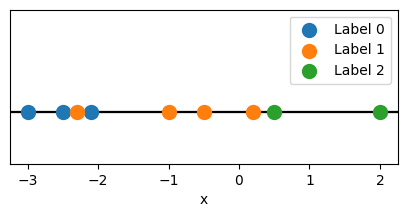

In [ ]:
xs = torch.tensor([-3, -2.5, -2.3, -2.1, -1, -0.5, 0.2, 0.5, 2]).view(-1, 1)
labels = torch.tensor([0, 0, 1, 0, 1, 1, 1, 2, 2])
assert len(xs) == len(labels)

fig, ax = plt.subplots(figsize=(5,2))
for i in range(3):
	x = xs[labels == i]
	ax.axhline(0, color='k')
	ax.scatter(x, [0]*len(x), label=f'Label {i}', s=100,zorder=10)
	ax.set_ylim(-1, 2)
	ax.set_yticks([])
	ax.set_xlabel('x')
	ax.legend()

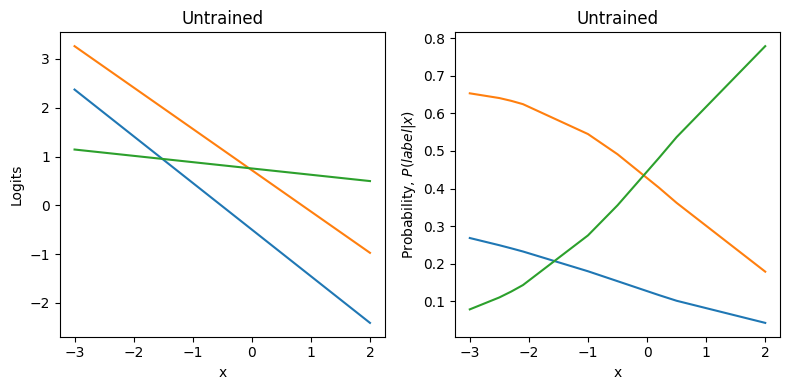

In [ ]:
class Classifier(torch.nn.Module):
	def __init__(self, n_features=1, n_classes=3):
		super().__init__()
		self.fc1 = torch.nn.Linear(n_features, n_classes)
	def forward(self, x):
		x = self.fc1(x)
		return x
	
model = Classifier()

fig, axes = plt.subplots(1,2,figsize=(8,4))

Nlabels = 3
ys = model(xs)
with torch.no_grad():
	for i in range(Nlabels):
		axes[0].plot(xs, ys[:,i])

ys = torch.softmax(model(xs), dim=1) # <---
with torch.no_grad():
	for i in range(Nlabels):
		axes[1].plot(xs, ys[:,i])

for ax in axes:
	ax.set_title('Untrained')
	ax.set_xlabel('x')
axes[0].set_ylabel('Logits')
axes[1].set_ylabel('Probability, '+r'$P(label|x)$')
fig.tight_layout()

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

xvals_tensor = torch.tensor(xs, dtype=torch.float32).view (-1,1)
yvals_tensor = torch.tensor(labels, dtype=torch.long) # <---- important !
dataset = TensorDataset(xvals_tensor, yvals_tensor)
loader = DataLoader(dataset, batch_size=len(dataset))
for xb , lb in loader:
	print("x’s:", xb.T)
	print('labels:', lb)
	break

x’s: tensor([[-3.0000, -2.5000, -2.3000, -2.1000, -1.0000, -0.5000,  0.2000,  0.5000,
          2.0000]])
labels: tensor([0, 0, 1, 0, 1, 1, 1, 2, 2])


C:\Users\emilk\AppData\Local\Temp\ipykernel_41372\3855383564.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  xvals_tensor = torch.tensor(xs, dtype=torch.float32).view (-1,1)
C:\Users\emilk\AppData\Local\Temp\ipykernel_41372\3855383564.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  yvals_tensor = torch.tensor(labels, dtype=torch.long) # <---- important !


In [ ]:
def train(model, loader, N_epochs=100, lr=1e-2):
	criterion = torch.nn.CrossEntropyLoss ()
	optimizer = torch.optim.Adam(model.parameters(), lr=lr)
	for epoch in range(N_epochs):
		for xvals, labels in loader:
			logits = model(xvals)
			loss = criterion(logits, labels) # <--- cross -entropy
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()

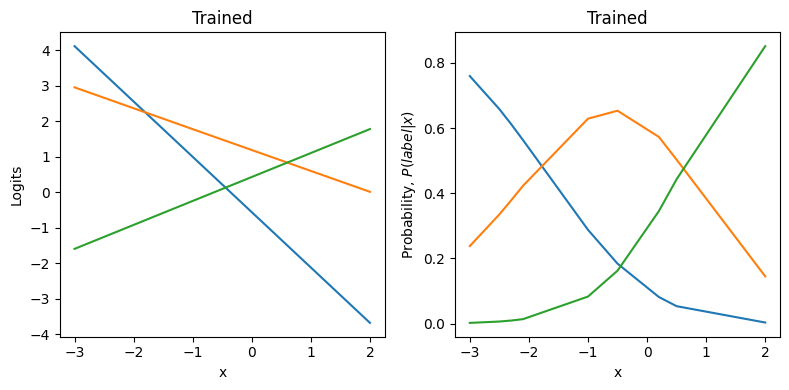

In [ ]:
train(model, loader)

fig, axes = plt.subplots(1,2,figsize=(8,4))
ys = model(xs)
with torch.no_grad():
	for i in range(Nlabels):
		axes[0].plot(xs, ys[:,i])

ys = torch.softmax(model(xs), dim=1) # <---
with torch.no_grad():
	for i in range(Nlabels):
		axes[1].plot(xs, ys[:,i])

for ax in axes:
	ax.set_title('Trained')
	ax.set_xlabel('x')
axes[0].set_ylabel('Logits')
axes[1].set_ylabel('Probability, '+r'$P(label|x)$')
fig.tight_layout()

In [ ]:
class LabelPredictor(Classifier):
	def predict_label(self, x):
		return torch.argmax(self.forward(x), dim=1)
labeler = LabelPredictor()

print(model(xs))

labeler.load_state_dict(model.state_dict())
model.state_dict(), labeler.state_dict()

tensor([[ 4.1143,  2.9540, -1.5958],
        [ 3.3348,  2.6597, -1.2583],
        [ 3.0230,  2.5420, -1.1233],
        [ 2.7112,  2.4243, -0.9883],
        [ 0.9962,  1.7768, -0.2458],
        [ 0.2167,  1.4825,  0.0917],
        [-0.8746,  1.0705,  0.5642],
        [-1.3423,  0.8939,  0.7667],
        [-3.6809,  0.0110,  1.7793]], grad_fn=<AddmmBackward0>)


(OrderedDict([('fc1.weight',
               tensor([[-1.5590],
                       [-0.5886],
                       [ 0.6750]])),
              ('fc1.bias', tensor([-0.5628,  1.1882,  0.4292]))]),
 OrderedDict([('fc1.weight',
               tensor([[-1.5590],
                       [-0.5886],
                       [ 0.6750]])),
              ('fc1.bias', tensor([-0.5628,  1.1882,  0.4292]))]))

x < -1.82: 0
-1.82 < x < 0.53: 1
x > 0.53: 2


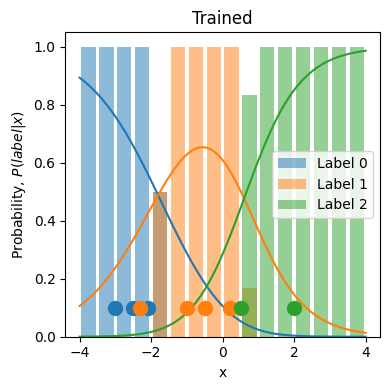

In [ ]:
fig, ax = plt.subplots(figsize=(4,4))


bin_edges = np.linspace(-4,4,17)
xs_lin = torch.linspace(-4,4,100).view(-1,1)
ys_lin = torch.softmax(model(xs_lin), dim=1)

labels = labeler.predict_label(xs_lin)
bars_all_labels, _ = np.histogram(xs_lin, bin_edges)
bars_all_labels[bars_all_labels==0] = 1
for i in range(Nlabels):
	x0s = xs_lin[labels == i]
	bars, xi = np. histogram(x0s, bin_edges)
	xi_centers = (xi[1:] + xi[: -1]) / 2
	ax.bar(xi_centers , bars/bars_all_labels, width=0.4, color=f'C{i}', alpha=0.5, label=f'Label {i}')


with torch.no_grad():
	for i in range(Nlabels):
		ax.plot(xs_lin, ys_lin[:,i])
ax.set_title('Trained')
ax.set_xlabel('x')
ax.set_ylabel('Probability, '+r'$P(label|x)$')
ax.legend(loc='center right')
fig.tight_layout()

label01 = xs_lin[labels == 0][-1]
label12 = xs_lin[labels == 1][-1]

print(f'x < {label01.item():.2f}: 0')
print(f'{label01.item():.2f} < x < {label12.item():.2f}: 1')
print(f'x > {label12.item():.2f}: 2')

labels = torch.tensor([0, 0, 1, 0, 1, 1, 1, 2, 2])
for i in range(3):
	x = xs[labels == i]
	ax.scatter(x, [0.1]*len(x), label=f'Label {i}', s=100,zorder=10, color=f'C{i}')

This plot illustrates how the trained model predicts on $x$-values. If $x<-1.82$, it will always predict (with 100% probability for every $x$-value) that the label is 0, and so on for roughly $-1.82<x<0.77$ and $x>0.77$.

In the figure, the transition between labels overlap in the histogram. It is not true that one x-values has the probability of two labels since we took the argmax. Before taking the argmax, one x-values *does* have more than one probabilty, given by the solid curves.

# W12B Classification of values for 2D scalar fields

In [155]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

### Three Gaussians: Dataset

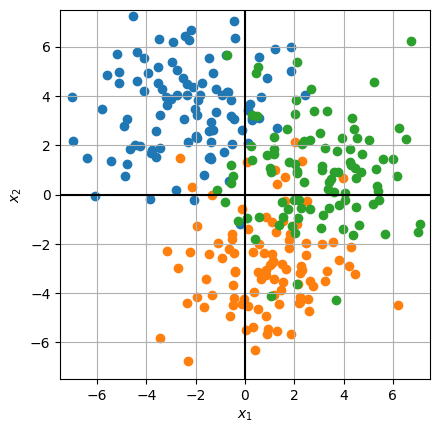

In [ ]:
torch.manual_seed(42)

N_per_label = 100
X0 = 2 * torch.randn(N_per_label, 2) + torch.tensor([-2,3])
label0 = torch.zeros(N_per_label)
X1 = 2 * torch.randn(N_per_label, 2) + torch.tensor([0.5,-3])
label1 = torch.zeros(N_per_label) + 1
X2 = 2 * torch.randn(N_per_label, 2) + torch.tensor([3,1])
label2 = torch.zeros(N_per_label) + 2

fig, ax = plt.subplots()
ax.scatter(X0[:, 0], X0[:, 1])
ax.scatter(X1[:, 0], X1[:, 1])
ax.scatter(X2[:, 0], X2[:, 1])
def plot_2Dspace(ax):
	ax.axhline(0, c='k')
	ax.axvline(0, c='k')
	ax.set_xlim(-7.5,7.5)
	ax.set_ylim(-7.5,7.5)
	ax.grid()
	ax.set_aspect('equal')
	ax.set_xlabel(r'$x_1$')
	ax.set_ylabel(r'$x_2$')
plot_2Dspace(ax)

### Classifier model: Predicting weights

In [ ]:
class Classifier(torch.nn.Module):
	def __init__(self, n_features=2, n_classes=3):
		super().__init__()
		self.fc1 = torch.nn.Linear(n_features, n_classes)
	def forward(self, x):
		x = self.fc1(x)
		return x

def train(model, loader, N_epochs=100, lr=1e-2):
	criterion = torch.nn.CrossEntropyLoss ()
	optimizer = torch.optim.Adam(model.parameters(), lr=lr)
	for epoch in range(N_epochs):
		for xvals, labels in loader:
			logits = model(xvals)
			loss = criterion(logits, labels) # <--- cross -entropy
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()

xs = torch.cat([X0, X1, X2], dim=0).float()  # equivalent to float32
ys = torch.cat([label0, label1, label2], dim=0).long()

dataset = TensorDataset(xs, ys)
loader = DataLoader(dataset, batch_size=len(dataset))

model = Classifier()
train(model, loader, 1000)

### Classifier model: Predicting labels

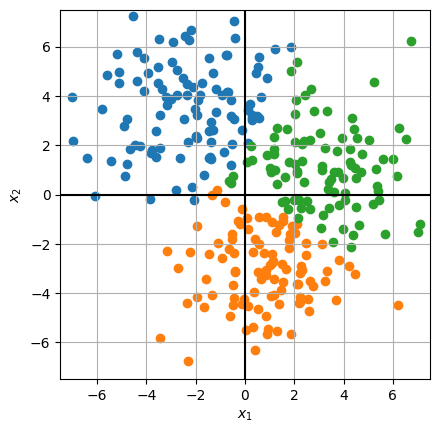

In [ ]:
class LabelPredictor(Classifier):
	def predict_label(self, x):
		return torch.argmax(self.forward(x), dim=1)
labeler = LabelPredictor()

labeler.load_state_dict(model.state_dict())

fig, ax = plt.subplots()
labels = labeler.predict_label(xs)
for i in range(3):
	xi = xs[labels == i]
	ax.scatter(xi[:, 0], xi[:, 1], label=f'Label {i}')
plot_2Dspace(ax)

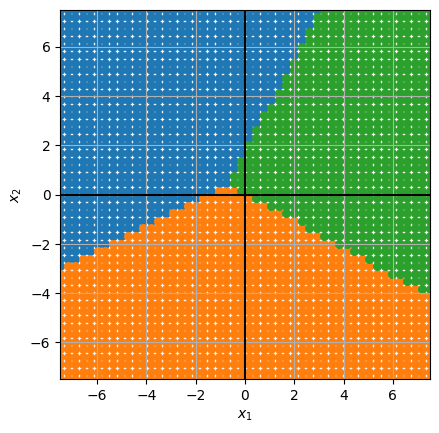

In [ ]:
xs_lin = torch.linspace(-7.5,7.5,50)
ys_lin = torch.linspace(-7.5,7.5,50)
X, Y = torch.meshgrid(xs_lin, ys_lin, indexing='xy')
grid = torch.stack([X.flatten(), Y.flatten()], dim=1)

fig, ax = plt.subplots()
labels = labeler.predict_label(grid)
for i in range(3):
	gridi = grid[labels == i]
	ax.scatter(gridi[:, 0], gridi[:, 1], label=f'Label {i}', s=30)
plot_2Dspace(ax)

### The Himmelblau function

In [222]:
f = lambda x1, x2 : (x1**2 + x2 - 11)**2 + (x1 + x2**2 - 7)**2

x_lin = torch.linspace(-7.5, 7.5, 50)
X, Y = torch.meshgrid(x_lin, x_lin, indexing='xy')
grid = torch.stack([X.flatten(), Y.flatten()], dim=1).float()

# the iteration over points mirrors the output!
# fx = torch.tensor([f(x1, x2) for x1 in x_lin for x2 in x_lin])
fx = f(X, Y).flatten()

y_labels = torch.zeros_like(fx)
y_labels[fx <= 25] = 0
y_labels[(fx > 25) & (fx <= 300)] = 1
y_labels[fx > 300] = 2
y_labels = y_labels.long()

dataset = TensorDataset(grid, y_labels)
loader = DataLoader(dataset, batch_size=len(dataset))

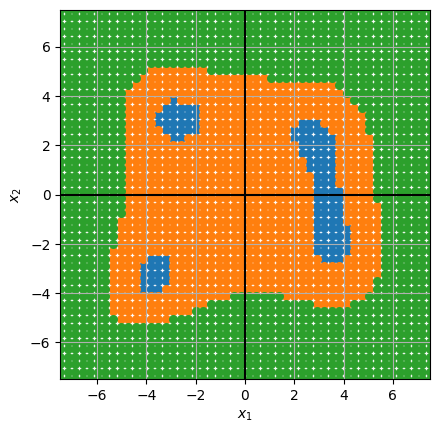

In [ ]:
fig, ax = plt.subplots()
for i in range(3):
	gridi = grid[y_labels == i]
	ax.scatter(gridi[:, 0], gridi[:, 1], label=f'Label {i}', s=30)
plot_2Dspace(ax)

Making train, validation, and test set

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_rest, y_train, y_rest = train_test_split(
	grid, y_labels, test_size=0.2, random_state=42, stratify=y_labels)

x_val, x_test, y_val, y_test = train_test_split(
	x_rest, y_rest, test_size=0.5, random_state=42, stratify=y_rest)

train_dataset = TensorDataset(x_train, y_train)
val_dataset = TensorDataset(x_val, y_val)
test_dataset = TensorDataset(x_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(len(train_dataset), len(val_dataset), len(test_dataset))

2000 250 250


In [ ]:
class ClassifierMultilayer(torch.nn.Module):
	def __init__(self, n_features=2, n_classes=3, hidden_dim=0, depth=0):
		super().__init__()
		if hidden_dim == 0:
			self.net = torch.nn.Sequential(torch.nn.Linear(n_features, n_classes))
		else:
			layers = []
			layers.append(torch.nn.Linear(n_features, hidden_dim))
			layers.append(torch.nn.SiLU())
			if depth > 2:
				for _ in range(depth-2):
					layers.append(torch.nn.Linear(hidden_dim, hidden_dim))
					layers.append(torch.nn.SiLU())
			layers.append(torch.nn.Linear(hidden_dim, n_classes))
			self.net = torch.nn.Sequential(*layers)
			
	def forward(self, x):
		x = self.net(x)
		return x

def train(model, train_loader, val_loader, test_loader, N_epochs=100, lr=1e-2):
	criterion = torch.nn.CrossEntropyLoss ()
	optimizer = torch.optim.Adam(model.parameters(), lr=lr)

	train_loss = []
	val_loss = []

	for epoch in range(N_epochs):

		### Training ###
		model.train()
		_train_loss = 0.0
		for xvals, labels in train_loader:
			logits = model(xvals)
			loss = criterion(logits, labels) # <--- cross -entropy
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
			_train_loss += loss.item() * xvals.size(0)
		_train_loss /= len(train_loader.dataset)
		train_loss.append(_train_loss)		

		### Validation ###
		model.eval()
		with torch.no_grad():
			_val_loss = 0.0
			for xvals, labels in val_loader:
				logits = model(xvals)
				_val_loss += criterion(logits, labels).item() * xvals.size(0)
			_val_loss /= len(val_loader.dataset)
			val_loss.append(_val_loss)

	### Test (after training) ###
	with torch.no_grad():
		test_loss = 0.0
		for xvals, labels in test_loader:
			logits = model(xvals)
			test_loss += criterion(logits, labels).item() * xvals.size(0)
		test_loss /= len(test_loader.dataset)

	return train_loss, val_loss, test_loss


class LabelPredictorMultilayer(ClassifierMultilayer):
	def predict_label(self, x):
		return torch.argmax(self.forward(x), dim=1)

**Model with input directly to output**

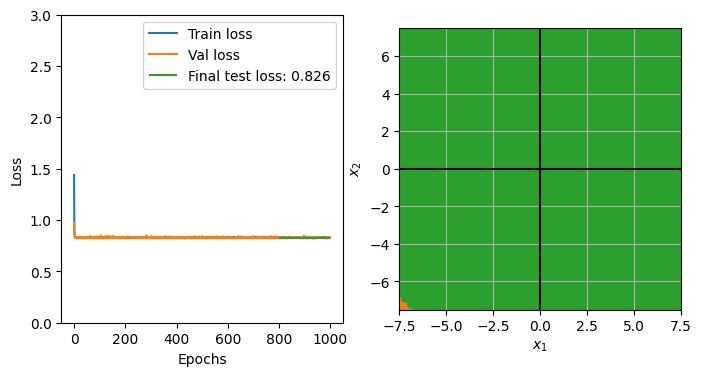

In [ ]:
model = ClassifierMultilayer()
train_loss, val_loss, test_loss = train(model, train_loader, val_loader, test_loader, 1000)
labeler = LabelPredictorMultilayer()
labeler.load_state_dict(model.state_dict())

fig, axes = plt.subplots(1,2,figsize=(8,4))

def plot_loss(ax, train_loss, val_loss, test_loss):
	ax.plot(torch.arange(len(train_loss)), train_loss, label='Train loss')
	ax.plot(torch.arange(len(val_loss)), val_loss, label='Val loss')
	ax.hlines(test_loss, 800, 1000, color='C2', label=f'Final test loss: {test_loss:.3f}')
	ax.set_xlabel('Epochs')
	ax.set_ylabel('Loss')
	# ax.set_yscale('log')
	ax.set_ylim(0, 3)
	ax.legend()

plot_loss(axes[0], train_loss, val_loss, test_loss)
labels = labeler.predict_label(grid)
for i in range(3):
	gridi = grid[labels == i]
	axes[1].scatter(gridi[:, 0], gridi[:, 1], label=f'Label {i}', s=30)
plot_2Dspace(axes[1])


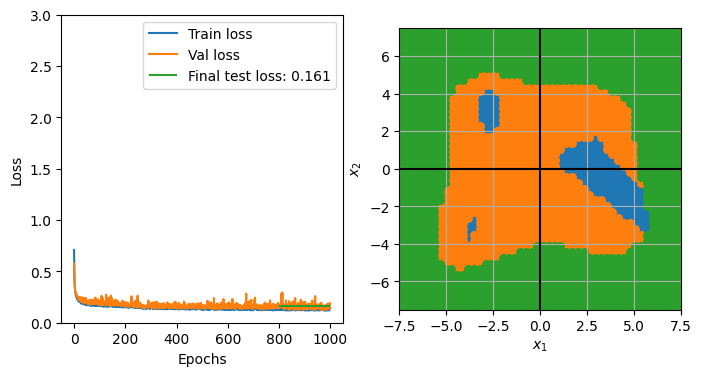

In [ ]:
model_1hl = ClassifierMultilayer(hidden_dim=10, depth=2)
train_loss, val_loss, test_loss = train(model_1hl, train_loader, val_loader, test_loader, 1000)
labeler = LabelPredictorMultilayer(hidden_dim=10, depth=2)
labeler.load_state_dict(model_1hl.state_dict())

fig, axes = plt.subplots(1,2,figsize=(8,4))

plot_loss(axes[0], train_loss, val_loss, test_loss)
labels = labeler.predict_label(grid)
for i in range(3):
	gridi = grid[labels == i]
	axes[1].scatter(gridi[:, 0], gridi[:, 1], label=f'Label {i}', s=30)
plot_2Dspace(axes[1])


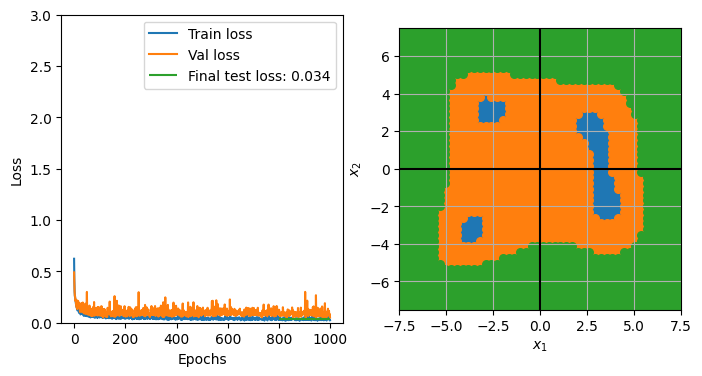

In [ ]:
model_2hl = ClassifierMultilayer(hidden_dim=10, depth=3)
train_loss, val_loss, test_loss = train(model_2hl, train_loader, val_loader, test_loader, 1000)
labeler = LabelPredictorMultilayer(hidden_dim=10, depth=3)
labeler.load_state_dict(model_2hl.state_dict())

fig, axes = plt.subplots(1,2,figsize=(8,4))

plot_loss(axes[0], train_loss, val_loss, test_loss)
labels = labeler.predict_label(grid)
for i in range(3):
	gridi = grid[labels == i]
	axes[1].scatter(gridi[:, 0], gridi[:, 1], label=f'Label {i}', s=30)
plot_2Dspace(axes[1])


*Discuss what it takes in terms of the neural network architecture to establish classifiers that can learn the labels as the present ones.*

At least one hidden layer is needed to get a feel for the scalar field. At least two hidden layers is required to get close to the correct labels.

# W12C Classifying 3-atomic clusters

3-atomic clusters with 4 labels:
1. Atoms on a straight line
2. Atoms form a bent line with 120deg angle
3. Atoms form a bent line with 90deg angle
4. Atoms form an equilateral triangle


In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from torch.utils.data import DataLoader, TensorDataset

In [ ]:
class AtomicCluster:
	def __init__(self, label, r0=[0,0], R_com=None, radius=0.5, pos=None):
		self.label = torch.as_tensor(label, dtype=torch.long)
		self.radius = radius

		if pos is not None:
			self.pos = torch.as_tensor(pos)
		else:
			if R_com is None:
				R_com = torch.randn(2)
			self.R_com = torch.as_tensor(R_com)

			self.r0 = torch.as_tensor(r0)
			self.r1, self.r2 = self._construct()

			pos = torch.stack([self.r0, *self.r1, *self.r2], dim=0) + self.R_com
			idx = torch.randperm(len(pos))
			self.pos = pos[idx]

	@property
	def get_com(self):
		return torch.mean(self.pos, dim=0)

	def _rotmat(self, theta):
		return torch.stack([torch.cos(theta), torch.sin(theta)], dim=1)
	
	def _construct(self):
		theta = 2*torch.pi*torch.rand(1)
		r1 = self.r0 + 2*self.radius*self._rotmat(theta)

		if self.label == 0: # 180 deg
			r2 = - r1
		elif self.label == 1: # 120 deg
			r2 = self.r0 + 2*self.radius*self._rotmat(theta+2*torch.pi/3)
		elif self.label == 2: # 90 deg
			r2 = self.r0 + 2*self.radius*self._rotmat(theta+torch.pi/2)
		elif self.label == 3: # 60 deg
			r2 = self.r0 + 2*self.radius*self._rotmat(theta+torch.pi/3)

		return r1, r2

	def plot(self, ax):
		color = ['C0', 'C1', 'C2', 'C3'][self.label]
		for i, r in enumerate(self.pos):
			circle = Circle(r, self.radius, facecolor=color, edgecolor='k')
			ax.add_patch(circle)
			ax.text(r[0].item(), r[1].item(), str(i+1),
					ha='center', va='center',
					fontsize=12, color='white',
					fontweight='bold')
		ax.set_xlim(-3,3)
		ax.set_ylim(-3,3)
		ax.set_xticks(torch.arange(-3,4))
		ax.set_yticks(torch.arange(-3,4))
		ax.set_title(f'label={self.label}')
		ax.set_aspect('equal')
		ax.grid()

Making train and validation set

In [ ]:
x_data = []
y_data = []
for i in range(4):
	for _ in range(225):
		ac = AtomicCluster(label=i)
		x_data.append(ac.pos)
		y_data.append(i)

x_data = torch.stack(x_data).float().flatten(start_dim=1)  # (x1, y1, x2, y2, x3, y3)
y_data = torch.tensor(y_data, dtype=torch.long)
print(x_data.shape)
print(y_data.shape)

from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
	x_data, y_data, test_size=100/900, random_state=42, stratify=y_data)

train_dataset = TensorDataset(x_train, y_train)
val_dataset = TensorDataset(x_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

for xvals, labels in train_loader:
	print(xvals.shape)
	print(labels.shape)
	break

print(len(train_dataset), len(val_dataset))

torch.Size([900, 6])
torch.Size([900])
torch.Size([32, 6])
torch.Size([32])
800 100


Plotting some of the train data

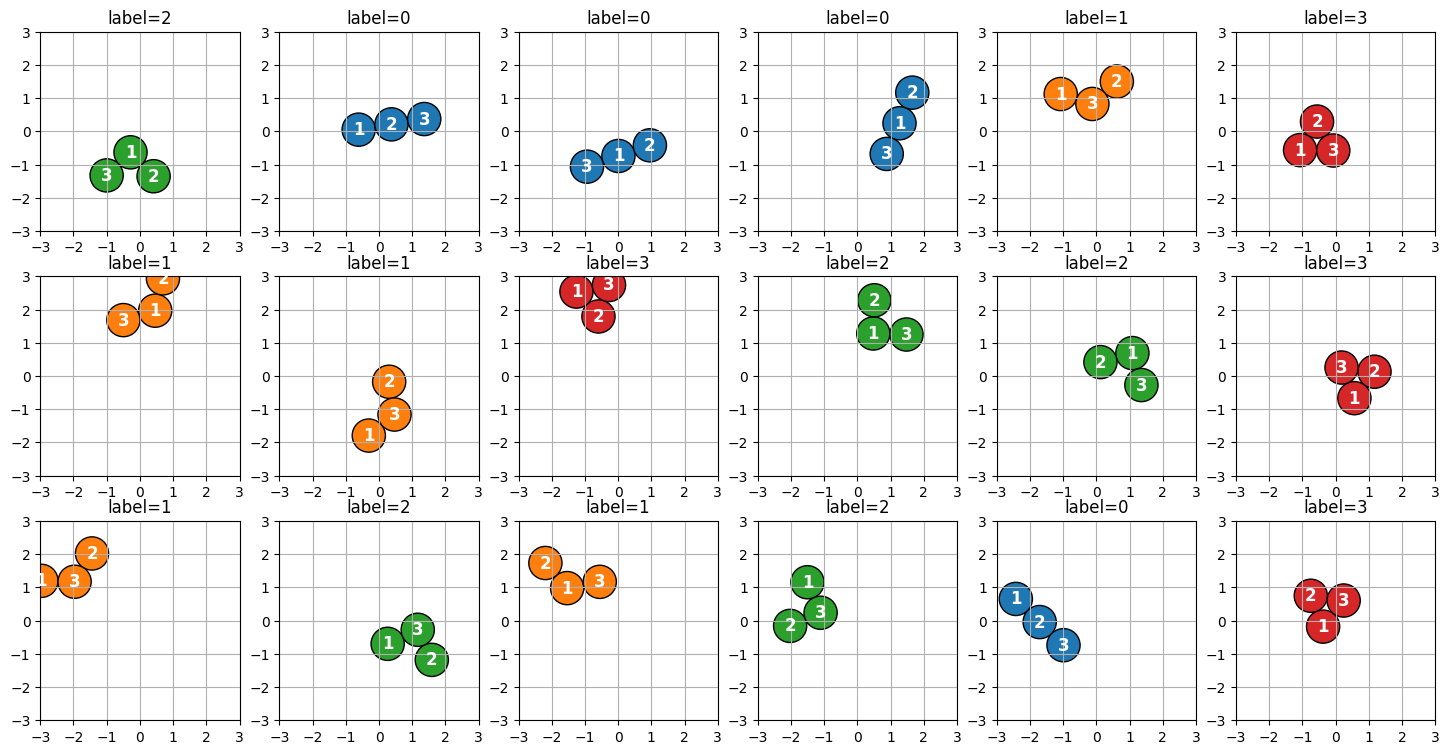

In [ ]:
fig, axes = plt.subplots(3,6,figsize=(18,9))
for i, ax in enumerate(axes.flatten()):
	pos, label = train_dataset[i]
	ac = AtomicCluster(label=label, pos=pos.reshape(3,2))
	ac.plot(ax)

### Classifier I: Too little data, too little network

In [ ]:
class ClassifierI(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.layer1 = torch.nn.Linear(6, 4)
		self.act1 = torch.nn.SiLU()
		self.layer2 = torch.nn.Linear(4, 4)
		
	def forward(self, x):
		h = self.layer1(x)
		z = self.act1(h)
		y = self.layer2(z)
		return y

def train(model, train_loader, val_loader, N_epochs=1000, lr=1e-2):
	criterion = torch.nn.CrossEntropyLoss ()
	optimizer = torch.optim.Adam(model.parameters(), lr=lr)

	train_loss = []
	val_loss = []

	for epoch in range(N_epochs):

		### Training ###
		model.train()
		_train_loss = 0.0
		for xvals, labels in train_loader:
			logits = model(xvals)
			loss = criterion(logits, labels) # <--- cross -entropy
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
			_train_loss += loss.item() * xvals.size(0)
		_train_loss /= len(train_loader.dataset)
		train_loss.append(_train_loss)		

		### Validation ###
		model.eval()
		with torch.no_grad():
			_val_loss = 0.0
			for xvals, labels in val_loader:
				logits = model(xvals)
				_val_loss += criterion(logits, labels).item() * xvals.size(0)
			_val_loss /= len(val_loader.dataset)
			val_loss.append(_val_loss)

	return train_loss, val_loss

class LabelPredictorI(ClassifierI):
	def predict_label(self, x):
		if x.ndim == 1:
			return torch.argmax(self.forward(x))
		else:
			return torch.argmax(self.forward(x), dim=1)

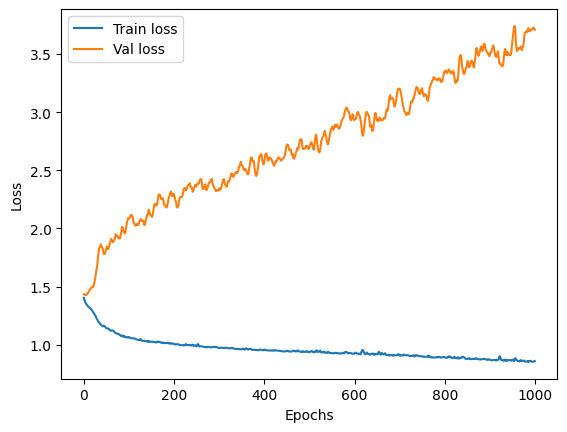

In [ ]:
small_train = TensorDataset(train_dataset.tensors[0][:100], train_dataset.tensors[1][:100])
small_train_loader = DataLoader(small_train, batch_size=32, shuffle=True)
modelI = ClassifierI()
train_loss_I, val_loss_I = train(modelI, small_train_loader, val_loader)

def plot_loss(ax, train_loss, val_loss):
	ax.plot(torch.arange(len(train_loss)), train_loss, label='Train loss')
	ax.plot(torch.arange(len(val_loss)), val_loss, label='Val loss')
	ax.set_xlabel('Epochs')
	ax.set_ylabel('Loss')
	# ax.set_yscale('log')
	ax.legend()

fig, ax = plt.subplots()
plot_loss(ax, train_loss_I, val_loss_I)

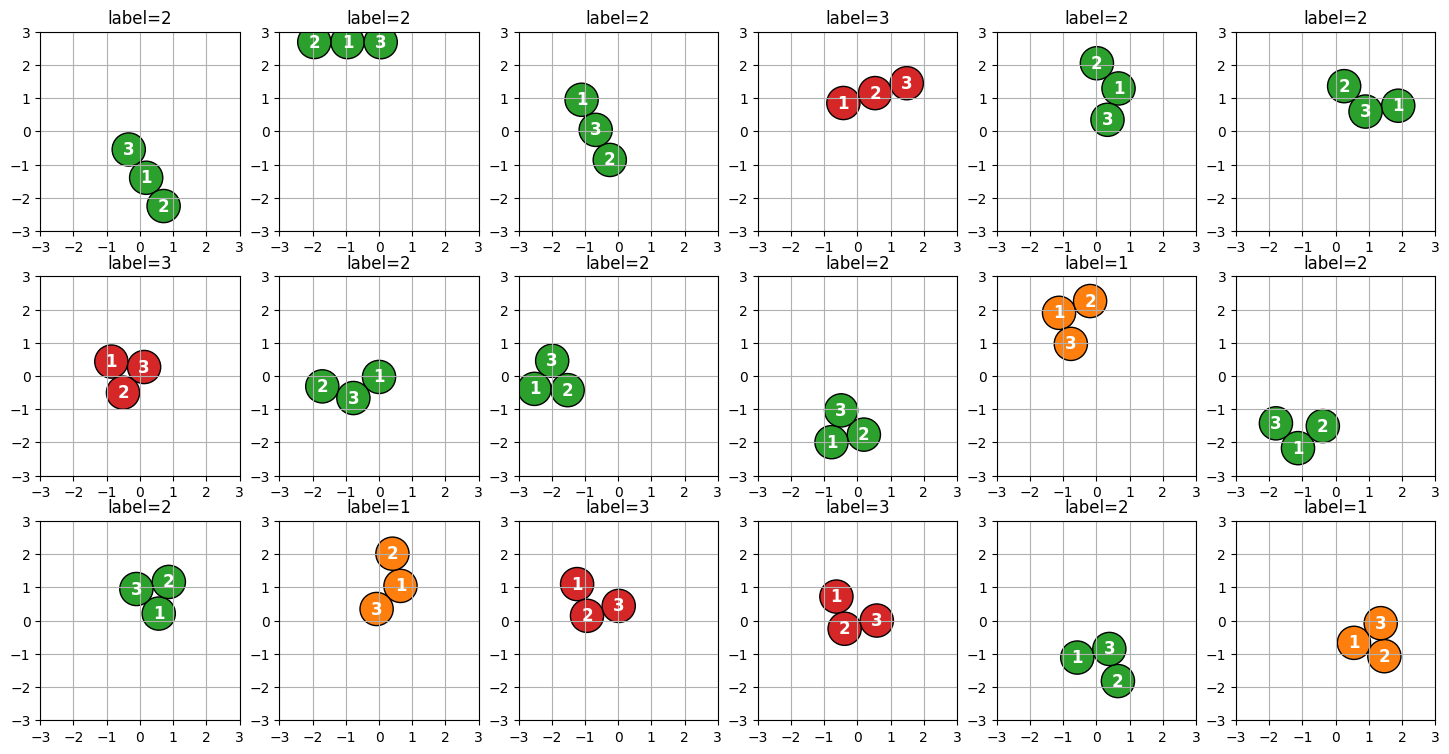

In [ ]:
fig, axes = plt.subplots(3,6,figsize=(18,9))
labelerI = LabelPredictorI()
labelerI.load_state_dict(modelI.state_dict())

for i, ax in enumerate(axes.flatten()):
	pos, _ = val_dataset[i]
	label = labelerI.predict_label(pos)
	ac = AtomicCluster(label=label.item(), pos=pos.reshape(3,2))
	ac.plot(ax)

The network does a very poor job of assigning labels to the validation data.

#### Confusion matrix

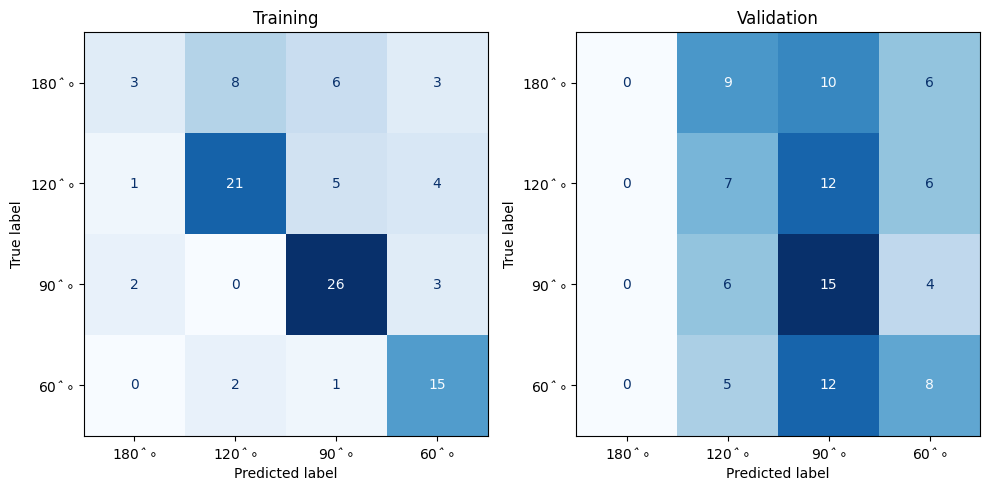

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1,2, figsize=(10,5))
for set, ax in zip([small_train, val_dataset], axes):
	pos = set.tensors[0]
	all_true = set.tensors[1]
	all_pred = labelerI.predict_label(pos)

	cm = confusion_matrix(all_true, all_pred)
	disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
								display_labels = [r'$180ˆ\circ$', r'$120ˆ\circ$', r'$90ˆ\circ$', r'$60ˆ\circ$'])
	disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
axes[0].set_title('Training')
axes[1].set_title('Validation')
fig.tight_layout()

I notice that the model labels many of the atomic clusters with label 3 (90 deg). That's why many of the clusters are green. This can also be seen in the confusion matrix for the validation set.

### Too little data, large enough network

In [ ]:
class ClassifierII(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.net = torch.nn.Sequential(torch.nn.Linear(6, 32),
									   torch.nn.SiLU(),
									   torch.nn.Linear(32, 32),
									   torch.nn.SiLU(),
									   torch.nn.Linear(32, 4))
		
	def forward(self, x):
		return self.net(x)

class LabelPredictorII(ClassifierII):
	def predict_label(self, x):
		if x.ndim == 1:
			return torch.argmax(self.forward(x))
		else:
			return torch.argmax(self.forward(x), dim=1)

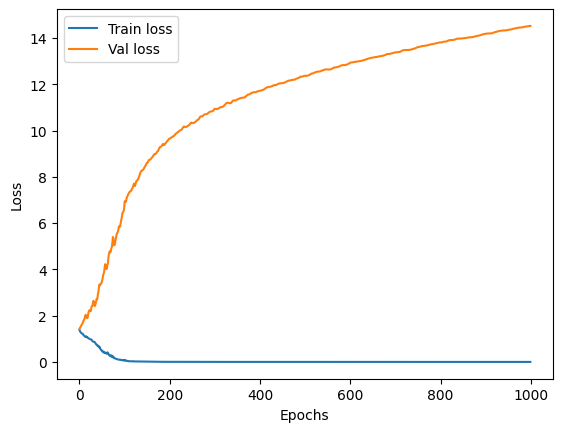

In [151]:
modelII = ClassifierII()
train_loss_II, val_loss_II = train(modelII, small_train_loader, val_loader)

fig, ax = plt.subplots()
plot_loss(ax, train_loss_II, val_loss_II)

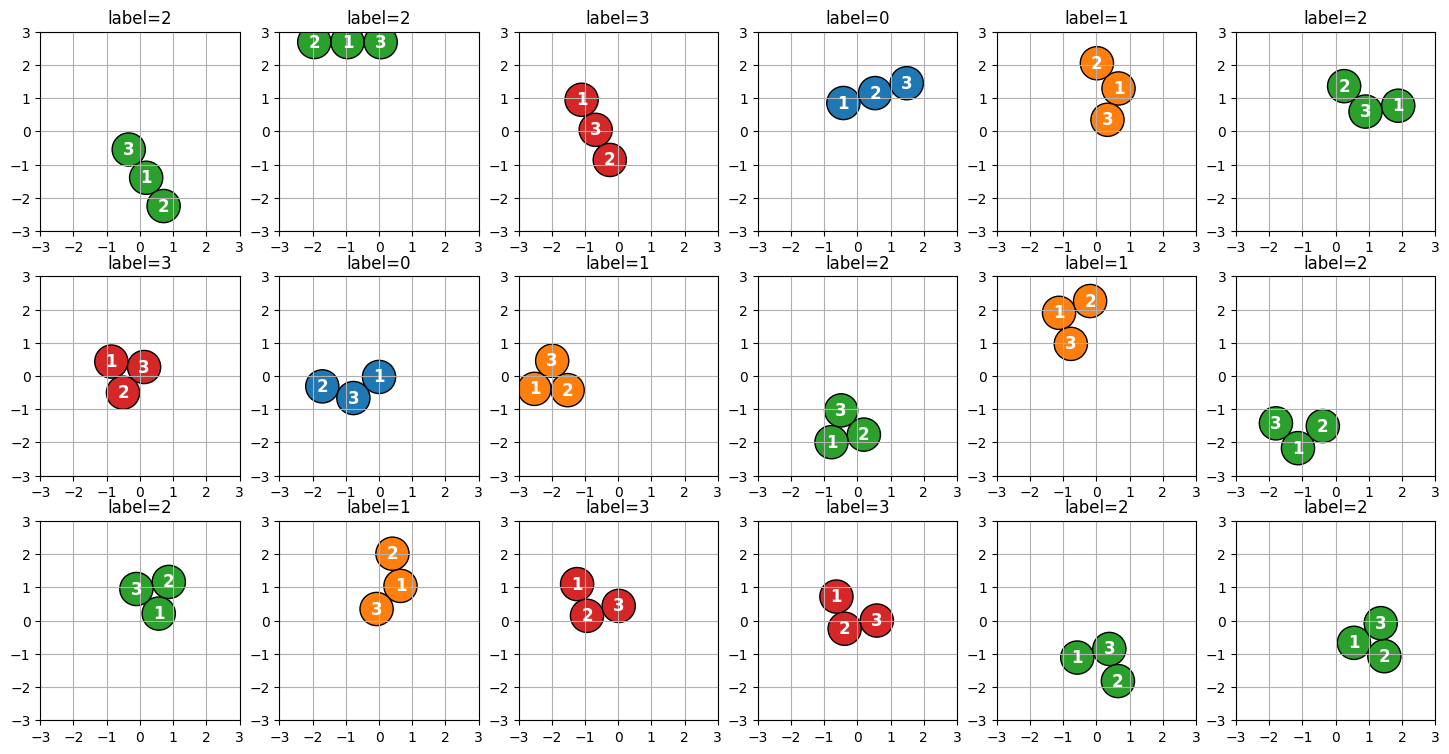

In [ ]:
fig, axes = plt.subplots(3,6,figsize=(18,9))
labelerII = LabelPredictorII()
labelerII.load_state_dict(modelII.state_dict())

for i, ax in enumerate(axes.flatten()):
	pos, _ = val_dataset[i]
	label = labelerII.predict_label(pos)
	ac = AtomicCluster(label=label.item(), pos=pos.reshape(3,2))
	ac.plot(ax)

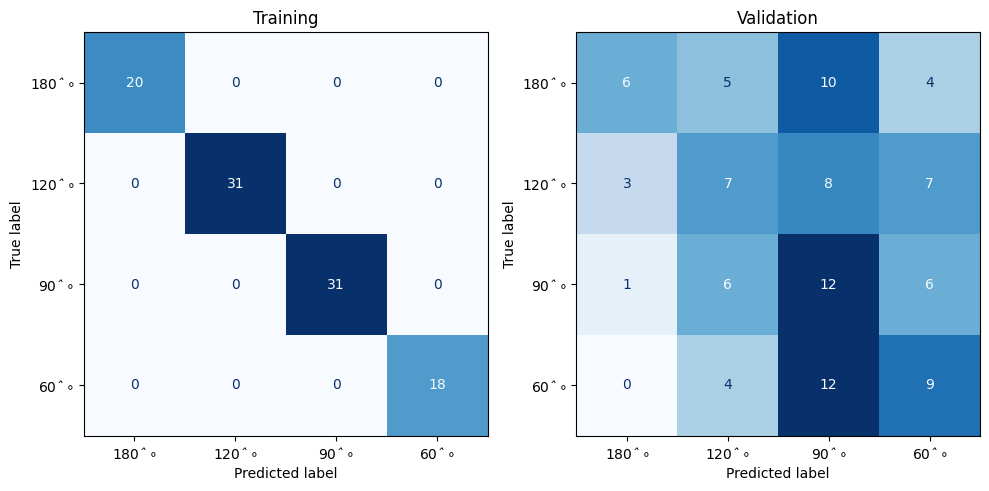

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(10,5))
for set, ax in zip([small_train, val_dataset], axes):
	pos = set.tensors[0]
	all_true = set.tensors[1]
	all_pred = labelerII.predict_label(pos)

	cm = confusion_matrix(all_true, all_pred)
	disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
								display_labels = [r'$180ˆ\circ$', r'$120ˆ\circ$', r'$90ˆ\circ$', r'$60ˆ\circ$'])
	disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
axes[0].set_title('Training')
axes[1].set_title('Validation')
fig.tight_layout()

The model is now big enough to *memorize* the small training dataset, and thus learns it very well. With the lack of more training data, the model fails to *generalize* its predictions.

### More data, large enough network

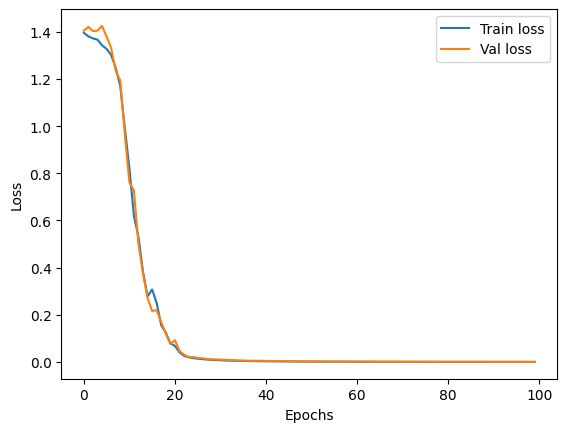

In [158]:
modelIII = ClassifierII()
train_loss_III, val_loss_III = train(modelIII, train_loader, val_loader, N_epochs=100)

fig, ax = plt.subplots()
plot_loss(ax, train_loss_III, val_loss_III)

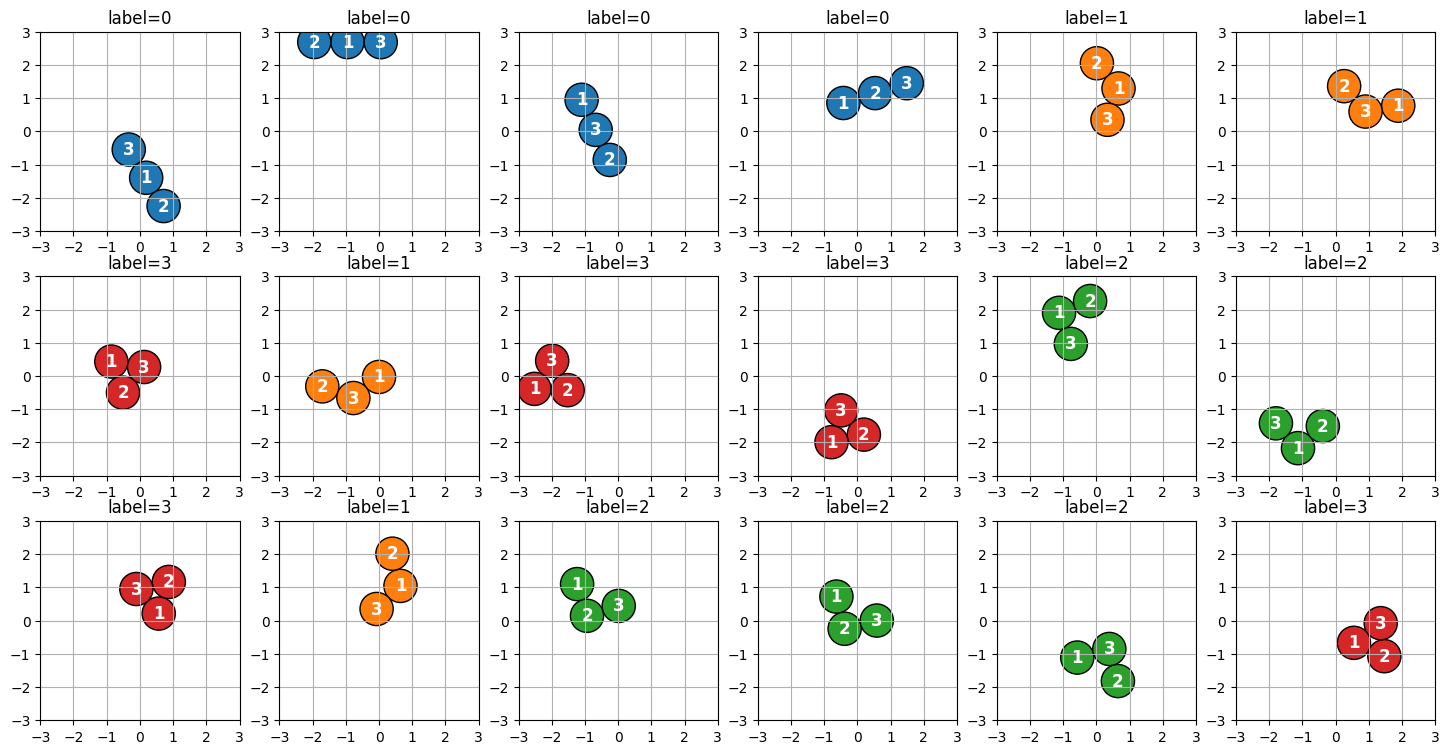

In [ ]:
fig, axes = plt.subplots(3,6,figsize=(18,9))
labelerIII = LabelPredictorII()
labelerIII.load_state_dict(modelIII.state_dict())

for i, ax in enumerate(axes.flatten()):
	pos, _ = val_dataset[i]
	label = labelerIII.predict_label(pos)
	ac = AtomicCluster(label=label.item(), pos=pos.reshape(3,2))
	ac.plot(ax)

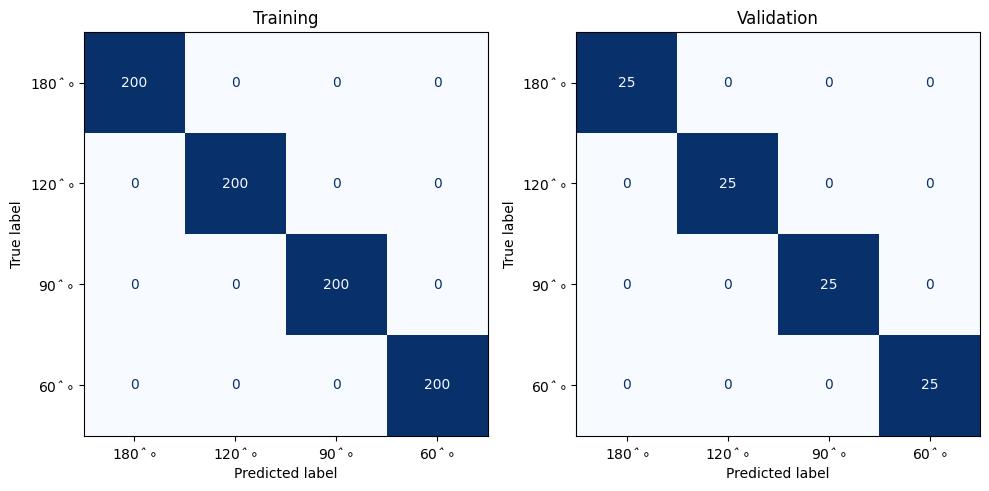

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(10,5))
for set, ax in zip([train_dataset, val_dataset], axes):
	pos = set.tensors[0]
	all_true = set.tensors[1]
	all_pred = labelerIII.predict_label(pos)

	cm = confusion_matrix(all_true, all_pred)
	disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
								display_labels = [r'$180ˆ\circ$', r'$120ˆ\circ$', r'$90ˆ\circ$', r'$60ˆ\circ$'])
	disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
axes[0].set_title('Training')
axes[1].set_title('Validation')
fig.tight_layout()

In just 100 epochs it generalizes perfectly. There is 200 and 25 in each box because I stratified the data.

### Rattled validation data

In [ ]:
rattled_x_val = []
for pos in x_val:
	noise = 0.1 * torch.randn_like(pos)
	rattled_x_val.append(pos+noise)
rattled_x_val = torch.stack(rattled_x_val).float()

rattled_val_dataset = TensorDataset(rattled_x_val, y_val)

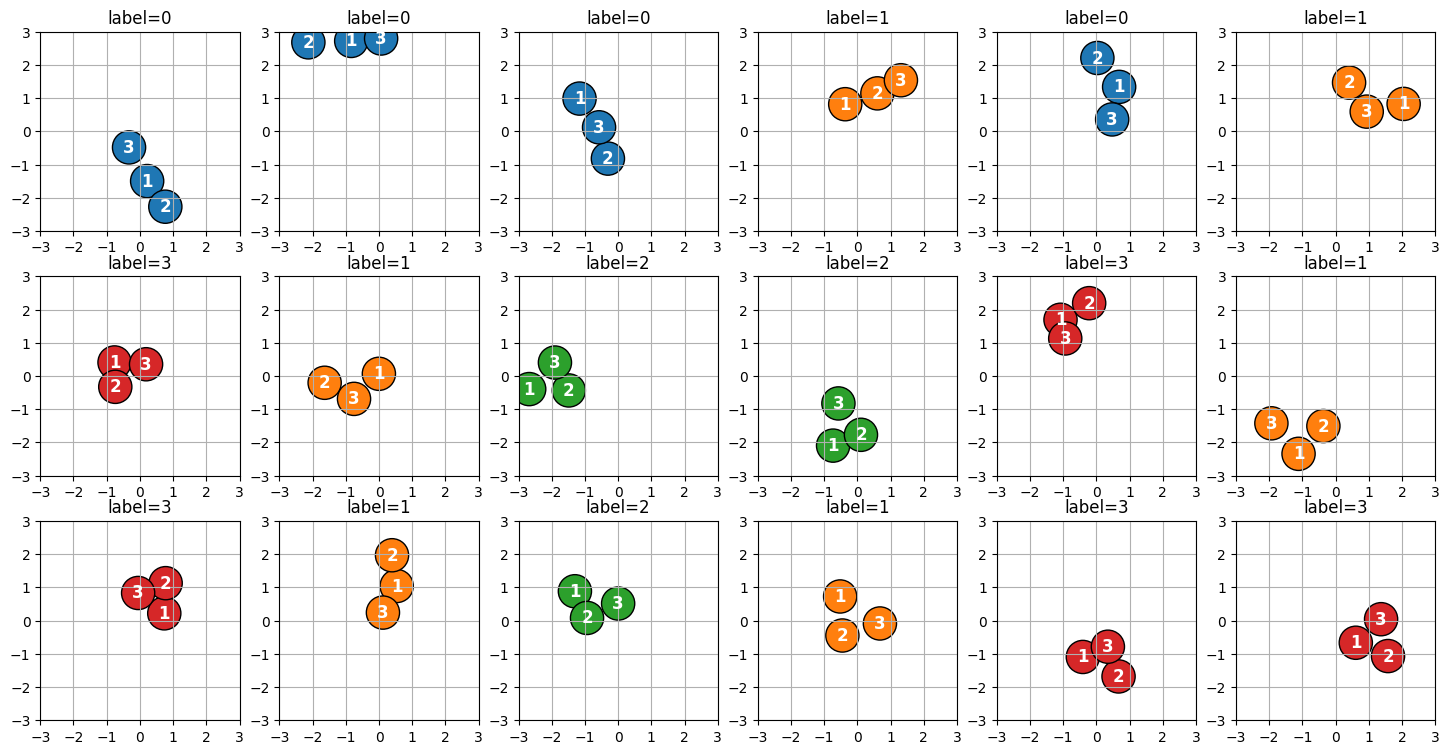

In [ ]:
fig, axes = plt.subplots(3,6,figsize=(18,9))

for i, ax in enumerate(axes.flatten()):
	pos, _ = rattled_val_dataset[i]
	label = labelerIII.predict_label(pos)
	ac = AtomicCluster(label=label.item(), pos=pos.reshape(3,2))
	ac.plot(ax)

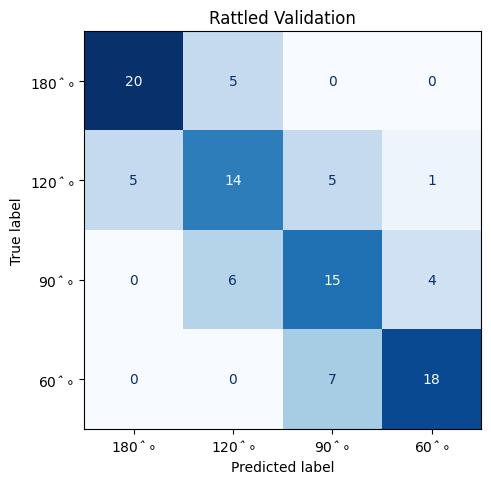

In [ ]:
fig, ax = plt.subplots(figsize=(5,5))

pos = rattled_val_dataset.tensors[0]
all_true = rattled_val_dataset.tensors[1]
all_pred = labelerIII.predict_label(pos)

cm = confusion_matrix(all_true, all_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
							display_labels = [r'$180ˆ\circ$', r'$120ˆ\circ$', r'$90ˆ\circ$', r'$60ˆ\circ$'])
disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)

ax.set_title('Rattled Validation')
fig.tight_layout()

Adding noise to all particles adds some noise to the predicted labels. The model might sometimes be on the edge between predicting label x vs label y, and thus it sometimes predicts the wrong label because the probability is just a little bit bigger.

We almost never see the model predicting in the extremes. The rattling could make an atomic cluster of label 2 (120deg) look more straight (label 1, 180 deg) or more curved (label 3, 90deg), and will almost never bring the atoms close enough to predict label 4 (60deg).

# W12D Classifying according to underlying pair-potential

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader, TensorDataset

### Calculator

In [2]:
class Calc(torch.nn.Module):
	def __init__(self, r0 = 1.0, a= 4.0, eps = 2.5, rcut = 1.0, lamb = 0.5,
				 gauss_r0 = np.sqrt(2.0), gauss_sig = 0.05, gauss_eps = -10.):
		super().__init__()
	
		# Learnable parameters
		self.r0 = torch.nn.Parameter(torch.tensor(r0))
		self.a = torch.nn.Parameter(torch.tensor(a))
		self.eps = torch.nn.Parameter(torch.tensor(eps))
		self.gauss_r0 = torch.nn.Parameter(torch.tensor(gauss_r0))
		self.gauss_sig = torch.nn.Parameter(torch.tensor(gauss_sig))
		self.gauss_eps = torch.nn.Parameter(torch.tensor(gauss_eps))
		self.rcut = torch.nn.Parameter(torch.tensor(rcut))
		self.lamb = torch.nn.Parameter(torch.tensor(lamb))
	
	def cosine_cutoff(self, r):
		f = torch.zeros_like(r)
		mask1 = r <= self.rcut
		mask2 = (r > self.rcut) & (r < self.rcut + self.lamb)
		f[mask1] = 1.0
		f[mask2] = 0.5 + 0.5 * torch.cos(torch.pi *(r[mask2] - self.rcut) / self.lamb)
		return f
	
	def V(self, r):
		f = self.cosine_cutoff(r)
		g = self.gauss_eps * torch.exp(-((r - self.gauss_r0)**2) / self.gauss_sig**2)
		morse = self.eps * ((1.0 - torch.exp(-self.a * (r - self.r0)))**2 - 1.0)
		return f * (g + morse)
	
	def forward(self, r):
		return self.V(r)

In [3]:
calc1 = Calc(r0=1.0, a=4.0, eps=2.5, rcut=10.0, lamb=0.1, gauss_r0=10., gauss_eps=0.)
calc2 = Calc(r0=1.0, a=4.0, eps=2.5, rcut=10.0, lamb=0.1, gauss_r0=1.4, gauss_eps= -0.75)
calc3 = Calc(r0=1.0, a=4.0, eps=2.5, rcut=1.0, lamb=0.5, gauss_r0=10., gauss_eps=0.)
calc4 = Calc(r0=1.0, a=4.0, eps=2.5, rcut=1.0, lamb=0.5, gauss_r0=1.3, gauss_eps= -3.)
for calc in [calc1, calc2, calc3, calc4]:
	for p in calc.parameters():
		p.requires_grad = False # "undoing" what nn. Parameters just did
	# you can also remove "nn.Parameters " above

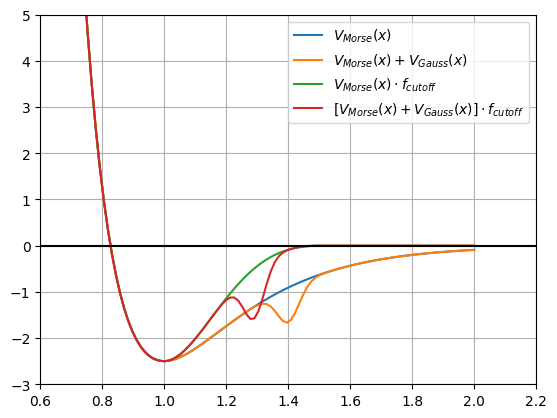

In [4]:
fig, ax = plt.subplots()
x_lin = torch.linspace(0.7,2,100)

ax.plot(x_lin, calc1(x_lin), label=r'$V_{Morse}(x)$')
ax.plot(x_lin, calc2(x_lin), label=r'$V_{Morse}(x)+V_{Gauss}(x)$')	
ax.plot(x_lin, calc3(x_lin), label=r'$V_{Morse}(x)\cdot f_{cutoff}$')
ax.plot(x_lin, calc4(x_lin), label=r'$\left[V_{Morse}(x)+V_{Gauss}(x)\right]\cdot f_{cutoff}$')	

ax.grid()
ax.legend()
ax.set_ylim(-3,5)
ax.set_xlim(0.6,2.2)
ax.axhline(0, color='k')


### Relaxation

In [5]:
class System(torch.nn.Module):
	def __init__(self, calc, positions):
		super().__init__()
		self.calc = calc
		self.positions = torch.nn.Parameter(positions)
											   
	def forward(self):
		return torch.sum(self.calc.V(torch.pdist(self.positions)))

	def draw(self, ax, color='C0', title=None):
		ax.scatter(self.positions.data[:, 0],
				   self.positions.data[:, 1], 
				   color=color, edgecolor='k', s=200)
		if title is not None:
			ax.set_title(title)
		ax.set_xlim(0, 10)
		ax.set_ylim(0, 10)
		ax.grid()

In [6]:
points = 3 + 4 * torch.rand(7,2)
system1 = System(calc1, points)
energy = system1()
energy.item()

747.5379638671875

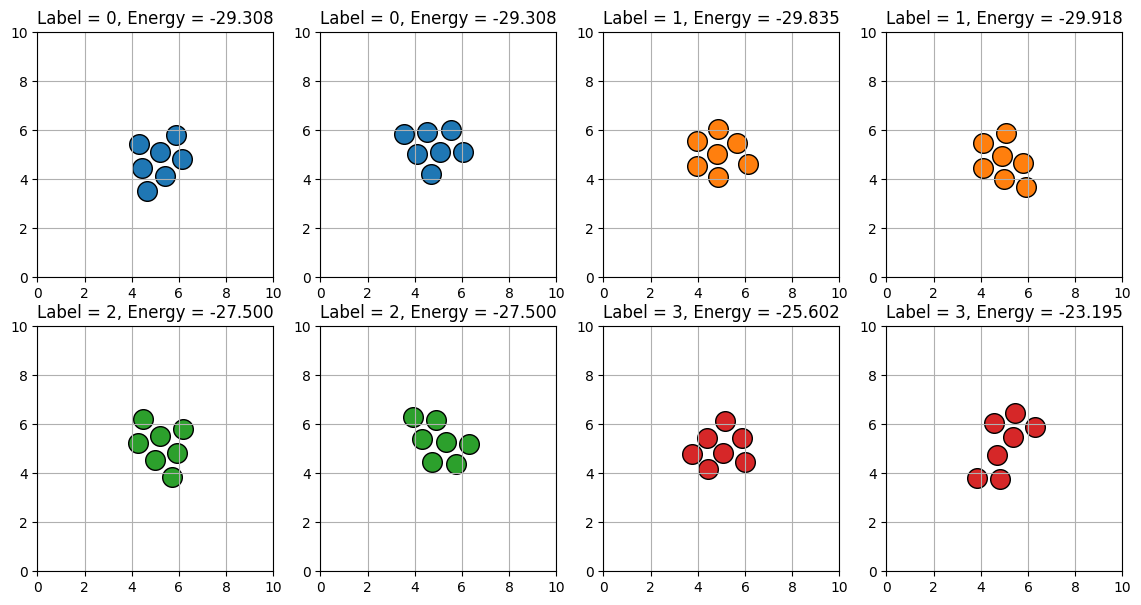

In [9]:
fig, axes = plt.subplots(2,4,figsize=(14,7))

def relax_structure(model):
	run_energy = 0.0
	while run_energy > -20:
	
		optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
		
		steps = 200
		for step in range(steps):
			optimizer.zero_grad() # wipe the previous calculated gradients
			energy = model()
			energy.backward()
			# to evade too large gradients for optimizer to handle, clip them like this
			torch.nn.utils.clip_grad_value_(model.parameters(), clip_value=0.5)
			optimizer.step()
		run_energy = energy.item()
	# print(f'Energy: {energy.item()}')
	return run_energy

for ax, calc, label in zip(axes.flatten(), 
						   [calc1, calc1, calc2, calc2, calc3, calc3, calc4, calc4], 
						   [0,0,1,1,2,2,3,3]):
	points = 4 + 2 * torch.rand(7,2)
	structure = System(calc, points)
	e = relax_structure(structure)

	c = ['C0', 'C1', 'C2', 'C3'][label]
	structure.draw(ax, color=c)
	ax.set_title(f'Label = {label}, Energy = {e:.3f}')


### Descriptor

In [ ]:
# from scipy.special import erf

class ConvolutedHist(System):
	def __init__(self, *args, sigma=0.1, dx=0.1, **kwargs):
		super().__init__ (*args, **kwargs)
		self.sigma = torch.as_tensor(sigma)
		self.dx = dx
		self.centers = torch.arange(0, 6+dx, dx)
	

	def histogram(self):
		dist_vector = torch.pdist(self.positions)
		erf_values = torch.stack([torch.erf((self.centers-ri+self.dx/2)/2**(1/2)/self.sigma) \
								  - torch.erf((self.centers-ri-self.dx/2)/2**(1/2)/self.sigma) \
								  for ri in dist_vector])
		hist = torch.sum(1/2*erf_values, axis=0)   # axis=0, only sum over rows, and get a list of sums.
		# self.total = sum(hist)
		return hist   # returns the bin counts

	def draw_hist(self, ax, color='C0', label=None):
		hist = self.histogram()

		with torch.no_grad():
			ax.bar(self.centers, hist, width=self.dx, color=color, label=label, edgecolor='k')
			ax.set_title('ConvolutedHist')
			ax.grid(alpha=0.3)
			ax.set_xlim(0,6)
			ax.set_ylim(0,6)

			if label is not None:
				ax.legend()

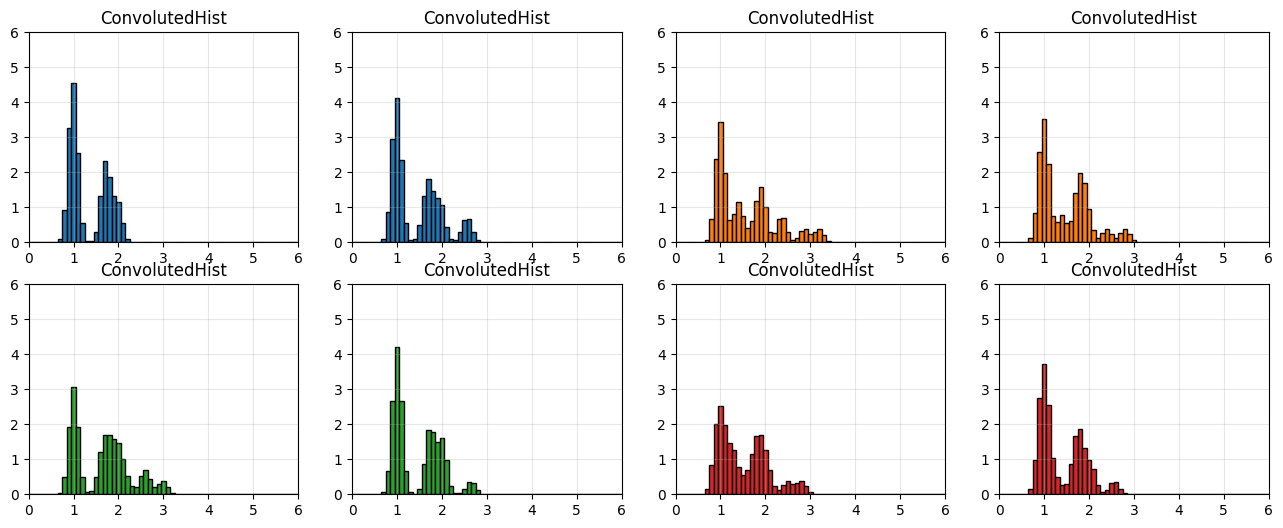

In [ ]:
fig, axes = plt.subplots(2,4,figsize=(16,6))
for ax, calc, label in zip(axes.flatten(), 
						   [calc1, calc1, calc2, calc2, calc3, calc3, calc4, calc4], 
						   [0,0,1,1,2,2,3,3]):
	points = 4 + 2 * torch.rand(7,2)
	structure = ConvolutedHist(calc=calc, positions=points, dx=0.1)
	relax_structure(structure)

	c = ['C0', 'C1', 'C2', 'C3'][label]
	structure.draw_hist(ax, color=c)

### Data

In [ ]:
x_data_cart_list = []
x_data_hist_list = []
y_data_list = []

for i, calc in enumerate([calc1, calc2, calc3, calc4]):
	for _ in range(100):
		points = 4 + 2 * torch.rand(7,2)
		structure = ConvolutedHist(calc=calc, positions=points, dx=0.1)
		relax_structure(structure)
		pos = structure.positions.detach().flatten()
		x_data_cart_list.append(pos)
		hist = structure.histogram().detach()
		x_data_hist_list.append(hist)
		y_data_list.append(i)
	print(f'calc{i+1} done')      

calc1 done
calc2 done
calc3 done
calc4 done


In [14]:
x_data_cart = torch.stack(x_data_cart_list)
x_data_hist = torch.stack(x_data_hist_list)
y_data = torch.as_tensor(y_data_list)

print(x_data_cart.shape)
print(x_data_hist.shape)
print(y_data.shape)

torch.Size([400, 14])
torch.Size([400, 61])
torch.Size([400])


Shuffle the data

In [ ]:
from sklearn.model_selection import train_test_split

x_train_cart, x_val_cart, y_train_cart, y_val_cart = train_test_split(
	x_data_cart, y_data, test_size=0.1, random_state=42, stratify=y_data)
x_train_hist, x_val_hist, y_train_hist, y_val_hist = train_test_split(
	x_data_hist, y_data, test_size=0.1, random_state=42, stratify=y_data)

train_dataset_cart = TensorDataset(x_train_cart, y_train_cart)
val_dataset_cart = TensorDataset(x_val_cart, y_val_cart)
train_dataset_hist = TensorDataset(x_train_hist, y_train_hist)
val_dataset_hist = TensorDataset(x_val_hist, y_val_hist)

train_loader_cart = DataLoader(train_dataset_cart, batch_size=32, shuffle=True)
val_loader_cart = DataLoader(val_dataset_cart, batch_size=32, shuffle=False)
train_loader_hist = DataLoader(train_dataset_hist, batch_size=32, shuffle=True)
val_loader_hist = DataLoader(val_dataset_hist, batch_size=32, shuffle=False)

for xvals, labels in train_loader_cart:
	print(xvals.shape)
	print(labels.shape)
	break
for xvals, labels in train_loader_hist:
	print(xvals.shape)
	print(labels.shape)
	break

print(len(train_dataset_hist), len(val_dataset_hist))
print(len(train_dataset_cart), len(val_dataset_cart))

torch.Size([32, 14])
torch.Size([32])
torch.Size([32, 61])
torch.Size([32])
360 40
360 40


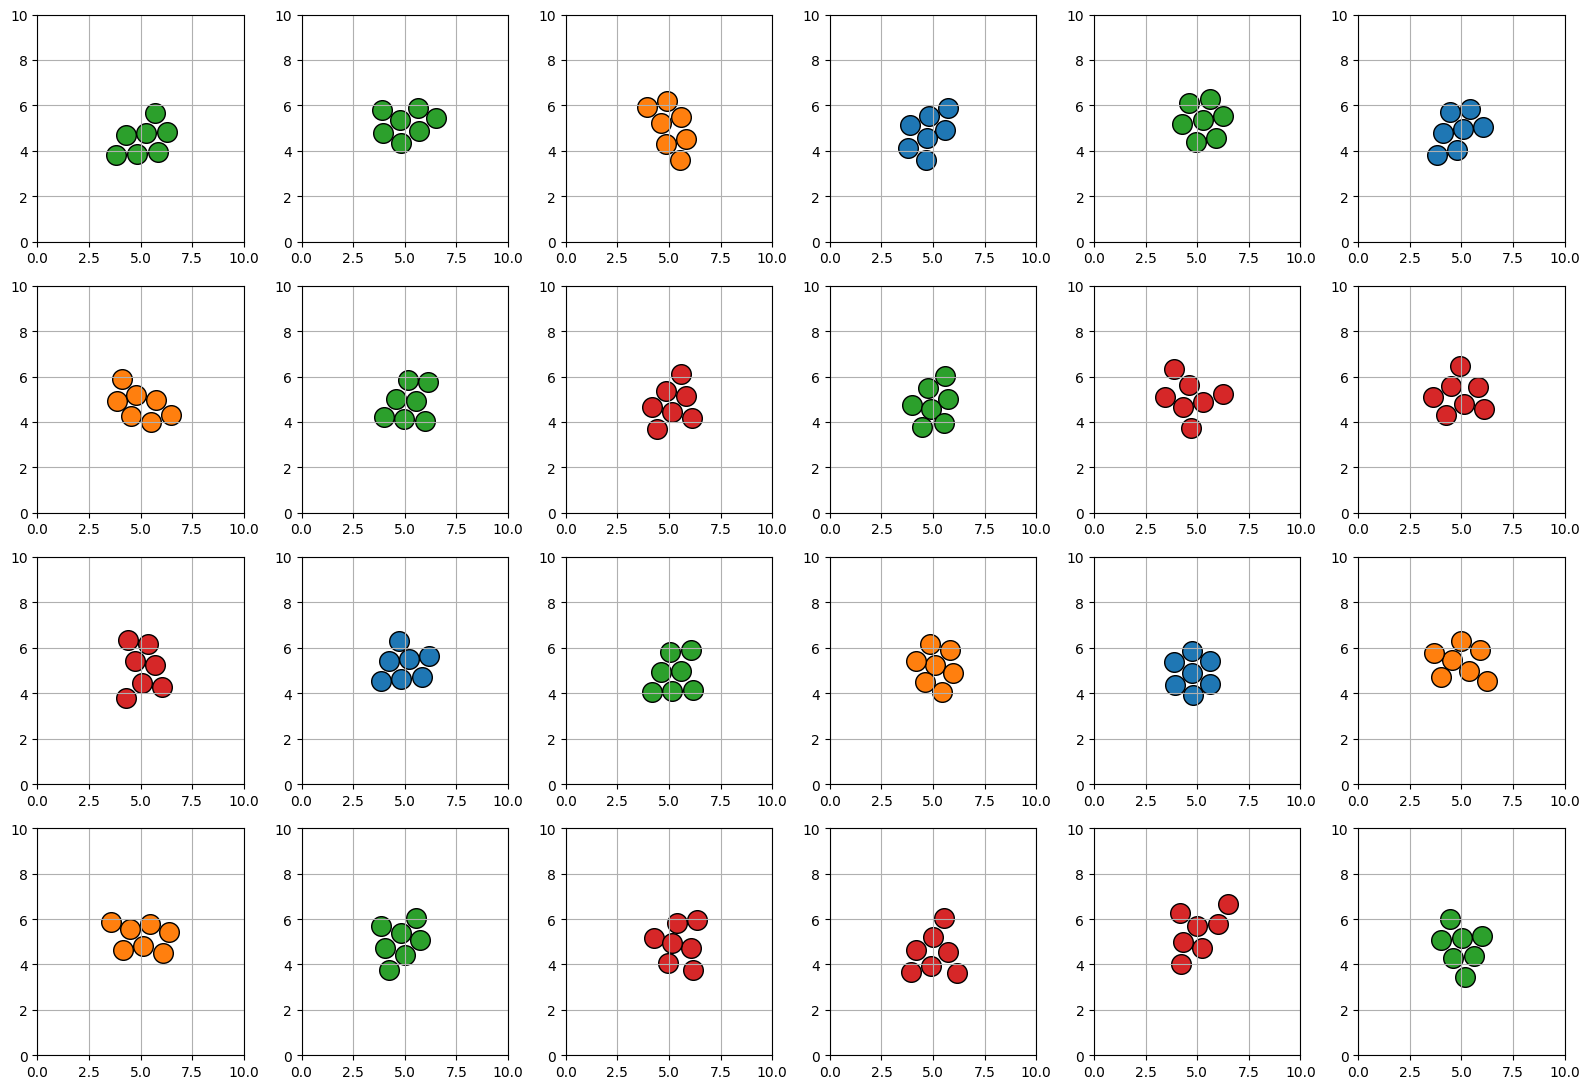

In [ ]:
fig, axes = plt.subplots(4,6,figsize=(16,11))

for i, ax in enumerate(axes.flatten()):
	pos = train_dataset_cart.tensors[0][i]
	label = train_dataset_cart.tensors[1][i]
	pos = pos.reshape(7,2)
	# calc is not important here for plotting
	system = ConvolutedHist(calc1, positions=pos)
	# the structures are already relaxed
	c = ['C0', 'C1', 'C2', 'C3'][label]
	system.draw(ax, color=c)
fig.tight_layout()

### Classifier using cartesian coordinates

In [ ]:
class ClassifierCart(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.net = torch.nn.Sequential(torch.nn.Linear(14, 64),
									   torch.nn.SiLU(),
									   torch.nn.Linear(64, 64),
									   torch.nn.SiLU(),
									   torch.nn.Linear(64, 4))
	def forward(self, x):
		return self.net(x)

	def predict_label(self, x):
		return torch.argmax(self.forward(x), dim=1)

In [ ]:
def train(model, train_loader, val_loader, N_epochs=1000, lr=1e-2):
	criterion = torch.nn.CrossEntropyLoss()
	optimizer = torch.optim.Adam(model.parameters(), lr=lr)

	train_loss = []
	val_loss = []
	for epoch in range(N_epochs):

		### Training ###
		model.train()
		_train_loss = 0.0
		for xvals, labels in train_loader:
			logits = model(xvals)
			loss = criterion(logits, labels) # <--- cross -entropy
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
			_train_loss += loss.item() * xvals.size(0)
		_train_loss /= len(train_loader.dataset)
		train_loss.append(_train_loss)		

		### Validation ###
		model.eval()
		with torch.no_grad():
			_val_loss = 0.0
			for xvals, labels in val_loader:
				logits = model(xvals)
				_val_loss += criterion(logits, labels).item() * xvals.size(0)
			_val_loss /= len(val_loader.dataset)
			val_loss.append(_val_loss)

	return train_loss, val_loss

In [114]:
model_cart = ClassifierCart()
train_loss_cart, val_loss_cart= train(model_cart, train_loader_cart, val_loader_cart, N_epochs=3000, lr=1e-3)
# print('Best epoch:', e)

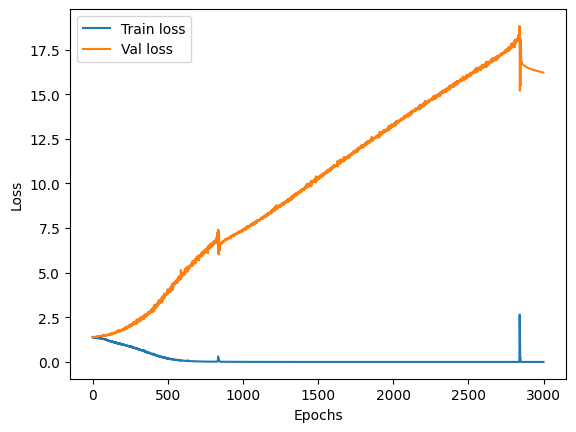

In [ ]:
fig, ax = plt.subplots()
def plot_loss(ax, train_loss, val_loss):
	ax.plot(torch.arange(len(train_loss)), train_loss, label='Train loss')
	ax.plot(torch.arange(len(val_loss)), val_loss, label='Val loss')
	ax.set_xlabel('Epochs')
	ax.set_ylabel('Loss')
	# ax.set_yscale('log')
	ax.legend()
plot_loss(ax, train_loss_cart, val_loss_cart)

Correct predictions
12 / 40


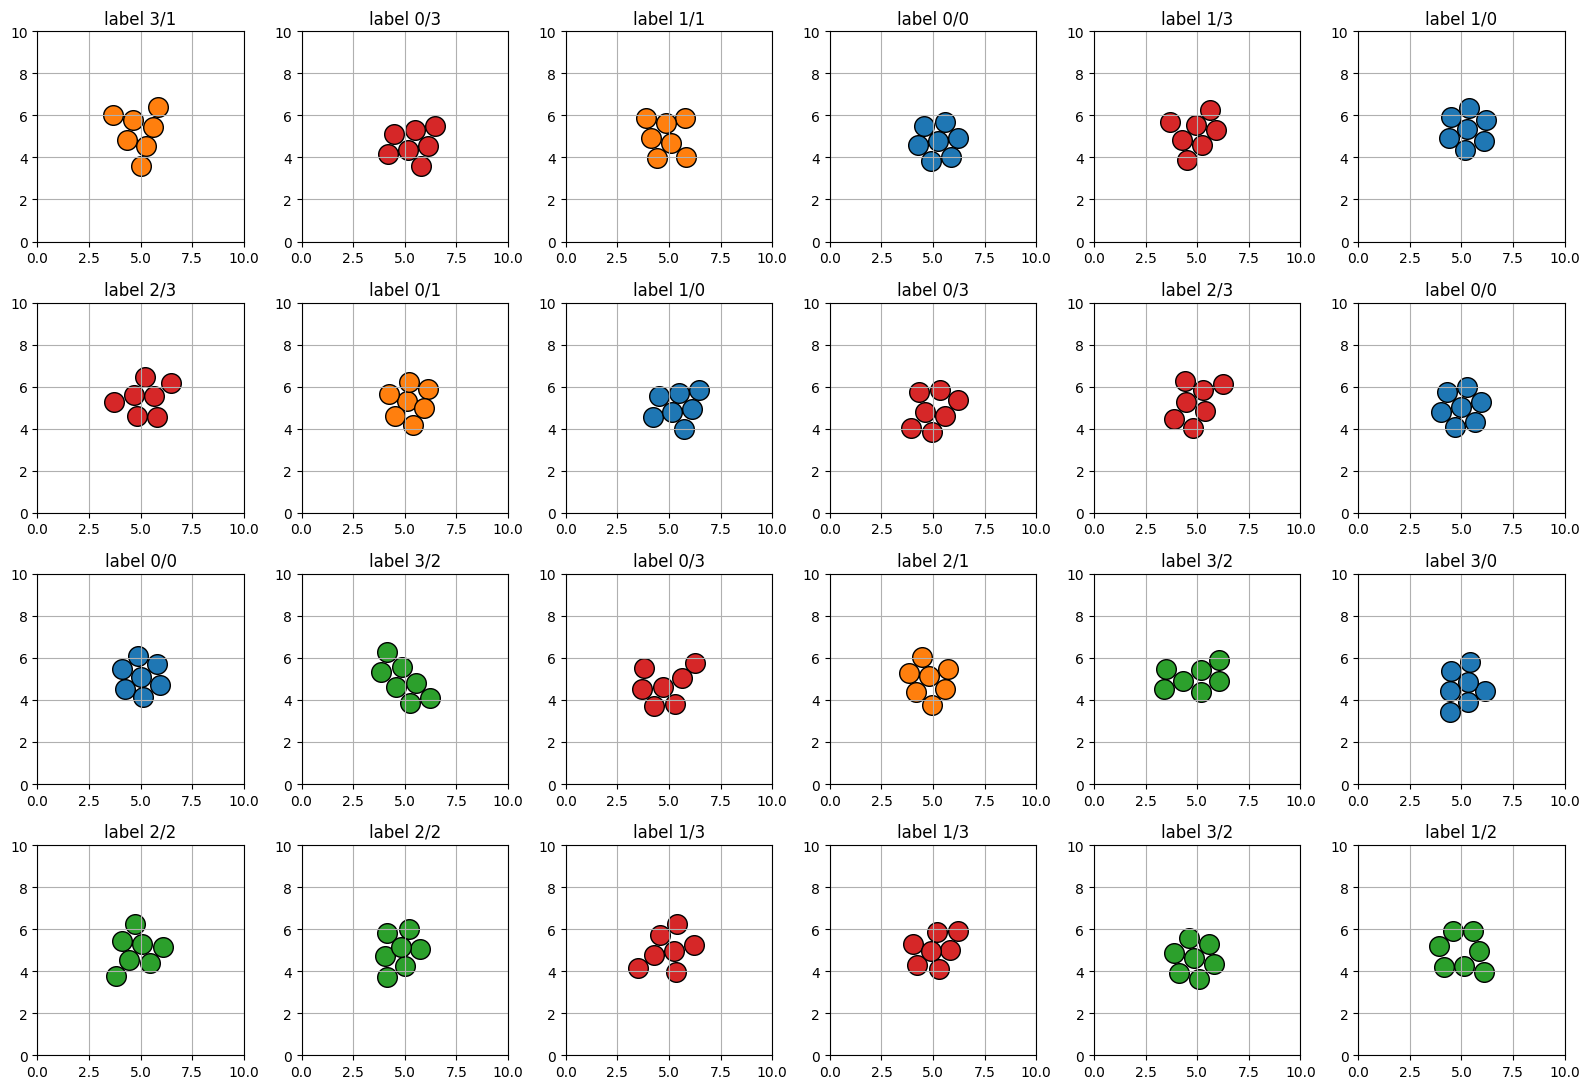

In [ ]:
fig, axes = plt.subplots(4,6,figsize=(16,11))

val_pos = val_dataset_cart.tensors[0]

pred_labels = model_cart.predict_label(val_pos)
true_labels = val_dataset_cart.tensors[1]

for i, ax in enumerate(axes.flatten()):
	pos = val_pos[i]
	pos = pos.reshape(7,2)
	pred_label = pred_labels[i]
	label = true_labels[i]
	# calc is not important here for plotting
	system = ConvolutedHist(calc1, positions=pos)
	# the structures are already relaxed
	c = ['C0', 'C1', 'C2', 'C3'][label]
	system.draw(ax, color=c, title=f'label {pred_label}/{label}')
fig.tight_layout()
print('Correct predictions')
print(sum([1 for pl, l in zip(pred_labels, true_labels) if pl == l]), '/', len(true_labels))

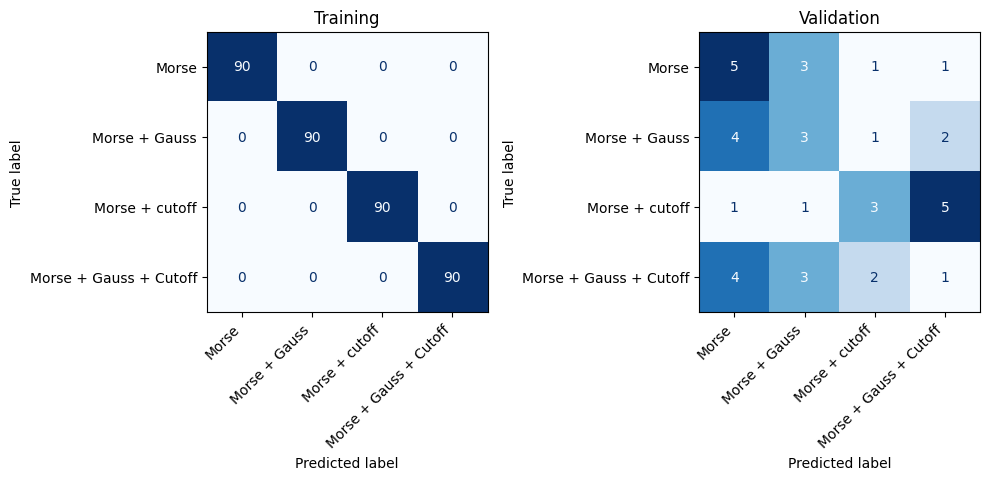

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1,2, figsize=(10,5))
for set, ax in zip([train_dataset_cart, val_dataset_cart], axes):
	pos = set.tensors[0]
	all_true = set.tensors[1]
	all_pred = model_cart.predict_label(pos)

	cm = confusion_matrix(all_true, all_pred)
	disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
								display_labels = ['Morse', 'Morse + Gauss', 'Morse + cutoff', 'Morse + Gauss + Cutoff'])
	disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
	ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
axes[0].set_title('Training')
axes[1].set_title('Validation')
fig.tight_layout()

*Conclude*

### Classifier using descriptor

In [ ]:
class ClassifierHist(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.net = torch.nn.Sequential(torch.nn.Linear(61, 64),
									   torch.nn.SiLU(),
									   torch.nn.Linear(64, 64),
									   torch.nn.SiLU(),
									   torch.nn.Linear(64, 4))
	def forward(self, x):
		return self.net(x)

	def predict_label(self, x):
		return torch.argmax(self.forward(x), dim=1)

In [ ]:
import copy

def train_bestmodel(model, train_loader, val_loader, N_epochs=1000, lr=1e-2):
	criterion = torch.nn.CrossEntropyLoss()
	optimizer = torch.optim.Adam(model.parameters(), lr=lr)

	train_loss = []
	val_loss = []
	best_val_loss = 1e10
	for epoch in range(N_epochs):

		### Training ###
		model.train()
		_train_loss = 0.0
		for xvals, labels in train_loader:
			logits = model(xvals)
			loss = criterion(logits, labels) # <--- cross -entropy
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
			_train_loss += loss.item() * xvals.size(0)
		_train_loss /= len(train_loader.dataset)
		train_loss.append(_train_loss)		

		### Validation ###
		model.eval()
		with torch.no_grad():
			_val_loss = 0.0
			for xvals, labels in val_loader:
				logits = model(xvals)
				_val_loss += criterion(logits, labels).item() * xvals.size(0)
			_val_loss /= len(val_loader.dataset)
			if _val_loss < best_val_loss:
				best_val_loss = _val_loss
				best_model = copy.deepcopy(model)
				best_epoch = epoch
			val_loss.append(_val_loss)

	model = best_model
	return train_loss, val_loss, best_epoch

In [104]:
model_hist = ClassifierHist()
train_loss_hist, val_loss_hist, e = train_bestmodel(model_hist, train_loader_hist, val_loader_hist, N_epochs=3000, lr=1e-3)
print('Best epoch:', e)

Best epoch: 2093


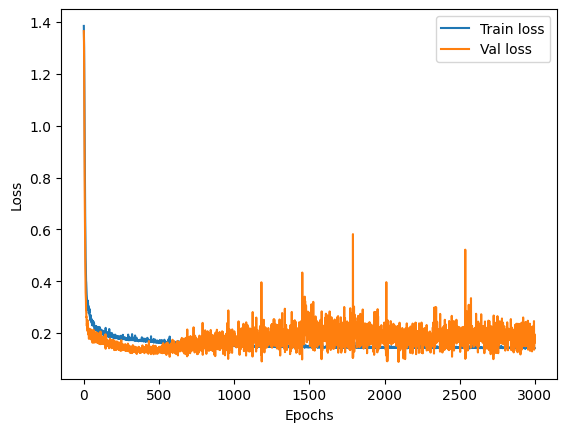

In [105]:
fig, ax = plt.subplots()
plot_loss(ax, train_loss_hist, val_loss_hist)

Correct predictions
38 / 40


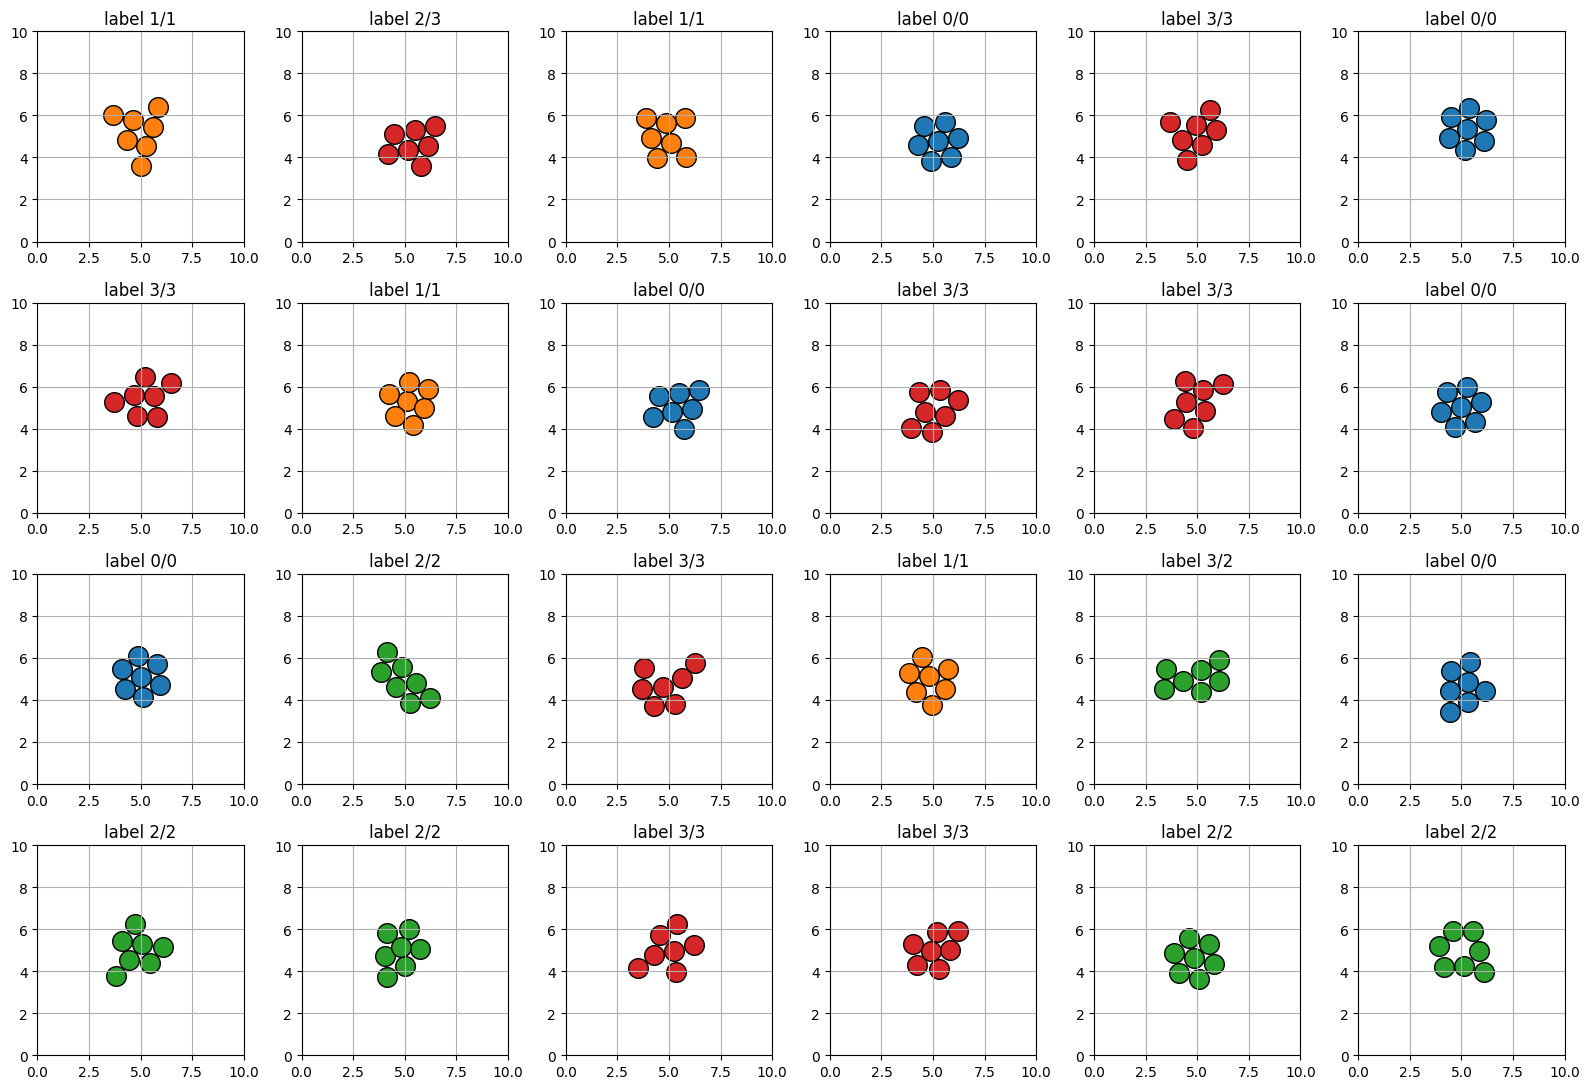

In [ ]:
fig, axes = plt.subplots(4,6,figsize=(16,11))

val_hist = val_dataset_hist.tensors[0]

pred_labels = model_hist.predict_label(val_hist)
true_labels = val_dataset_hist.tensors[1]

val_pos = val_dataset_cart.tensors[0]

for i, ax in enumerate(axes.flatten()):
	pos = val_pos[i]
	pos = pos.reshape(7,2)
	pred_label = pred_labels[i]
	label = true_labels[i]
	# calc is not important here for plotting
	system = ConvolutedHist(calc1, positions=pos)
	# the structures are already relaxed
	c = ['C0', 'C1', 'C2', 'C3'][label]
	system.draw(ax, color=c, title=f'label {pred_label}/{label}')
fig.tight_layout()
print('Correct predictions')
print(sum([1 for pl, l in zip(pred_labels, true_labels) if pl == l]), '/', len(true_labels))

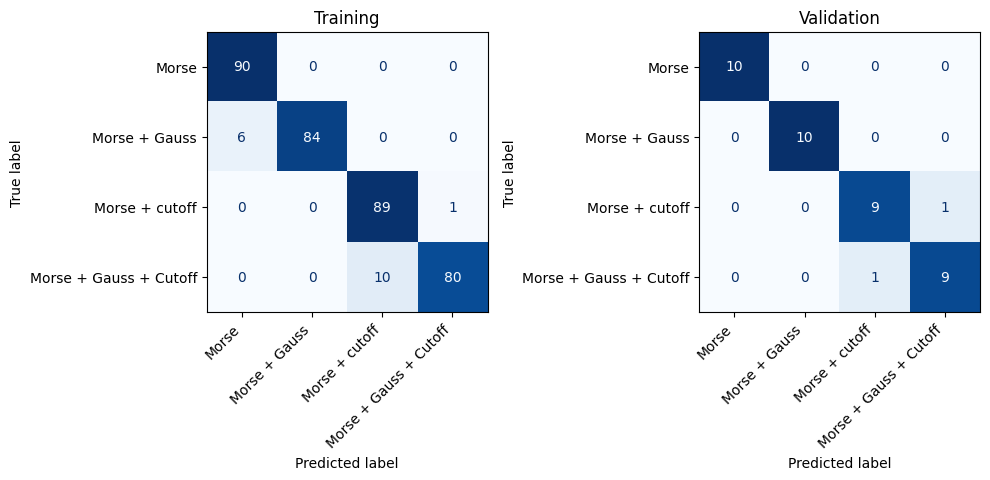

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1,2, figsize=(10,5))
for set, ax in zip([train_dataset_hist, val_dataset_hist], axes):
	pos = set.tensors[0]
	all_true = set.tensors[1]
	all_pred = model_hist.predict_label(pos)

	cm = confusion_matrix(all_true, all_pred)
	disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
								display_labels = ['Morse', 'Morse + Gauss', 'Morse + cutoff', 'Morse + Gauss + Cutoff'])
	disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
	ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
axes[0].set_title('Training')
axes[1].set_title('Validation')
fig.tight_layout()

*Conclude*

# W12E Classifying heptamers during relaxation

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

### Load and inspect the data

In [2]:
data = np.loadtxt("descriptor_class_heptamers_W12E.txt")
X = data [:, : -1].astype(np.float32)
y = data [:, -1].astype(np.int64)

print("Number of structures:", len(X))
print("Number of descriptor values:", X.shape[1])
print("Classes present:", np.unique(y))

X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

Number of structures: 1000
Number of descriptor values: 17
Classes present: [0 1 2 3 4 5 6 7 8 9]


In [3]:
from torch.utils.data import TensorDataset, DataLoader

X_train = X[:800]
y_train = y[:800]

X_val = X[800:]
y_val = y[800:]

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

### Construct the classifier

In [4]:
class Classifier(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.net = torch.nn.Sequential(torch.nn.Linear(17, 32),
									   torch.nn.SiLU(),
									   torch.nn.Linear(32, 32),
									   torch.nn.SiLU(),
									   torch.nn.Linear(32, 10))
	def forward(self, x):
		return self.net(x)

	def predict_label(self, x):
		if x.dim() == 1:
			return torch.argmax(self.forward(x))
		else:
			return torch.argmax(self.forward(x), dim=1)

The output layer gives logits, and not probabilities. CrossEntropyLoss should recieve logits since this gives less restrictions for the model to consider, like summing to 1 and being positive.

### Train in stages

We want to train in stages, and for each stage start from the best model from the stage.

In [5]:
import copy

def train_bestmodel(model, train_loader, val_loader, N_epochs=1000, lr=1e-2):
	criterion = torch.nn.CrossEntropyLoss()
	optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4) #NOTE weight decay in this exercise

	train_loss = []
	val_loss = []
	best_val_loss = 1e10
	for epoch in range(N_epochs):

		### Training ###
		model.train()
		_train_loss = 0.0
		for xvals, labels in train_loader:
			logits = model(xvals)
			loss = criterion(logits, labels) # <--- cross -entropy
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
			_train_loss += loss.item() * xvals.size(0)
		_train_loss /= len(train_loader.dataset)
		train_loss.append(_train_loss)		

		### Validation ###
		model.eval()
		with torch.no_grad():
			_val_loss = 0.0
			for xvals, labels in val_loader:
				logits = model(xvals)
				_val_loss += criterion(logits, labels).item() * xvals.size(0)
			_val_loss /= len(val_loader.dataset)
			if _val_loss < best_val_loss:
				best_val_loss = _val_loss
				best_model = copy.deepcopy(model)
				best_epoch = epoch
			val_loss.append(_val_loss)

	return train_loss, val_loss, best_epoch, best_model

In [6]:
model = Classifier()
train_loss = []
val_loss = []
for lr in [1e-2, 1e-3, 1e-4]:
	tl, vl, e, model = train_bestmodel(model, train_loader, val_loader, N_epochs=500, lr=lr)
	print('Best epoch:',e,'\tlr =',lr)
	train_loss.extend(tl)
	val_loss.extend(vl)

Best epoch: 369 	lr = 0.01
Best epoch: 3 	lr = 0.001
Best epoch: 0 	lr = 0.0001


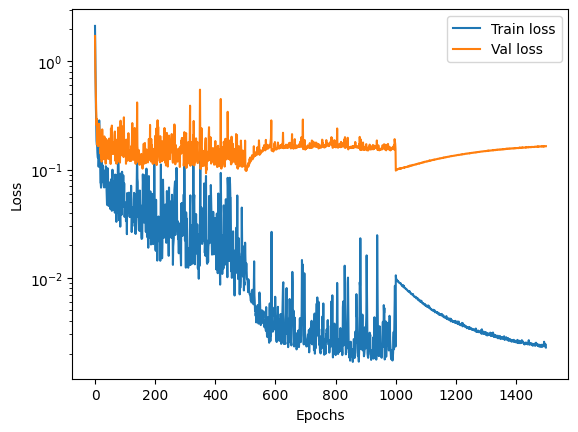

In [7]:
fig, ax = plt.subplots()
ax.plot(torch.arange(len(train_loss)), train_loss, label='Train loss')
ax.plot(torch.arange(len(val_loss)), val_loss, label='Val loss')
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')
ax.set_yscale('log')
ax.legend()

In the first stage, the best model is achieved very near the end.

In the second stage, it immediately begins overfitting, and the best model is obtained in the first few epochs.

In the final stage, the validation loss decreases very steadily, indicating that the small learning rate gives a very steady optimization. The final model, however, appears to be overfitted.

Continued optimization does not lower both loses in this case, it eventually begins to overfit the data.

### Assess the classifier

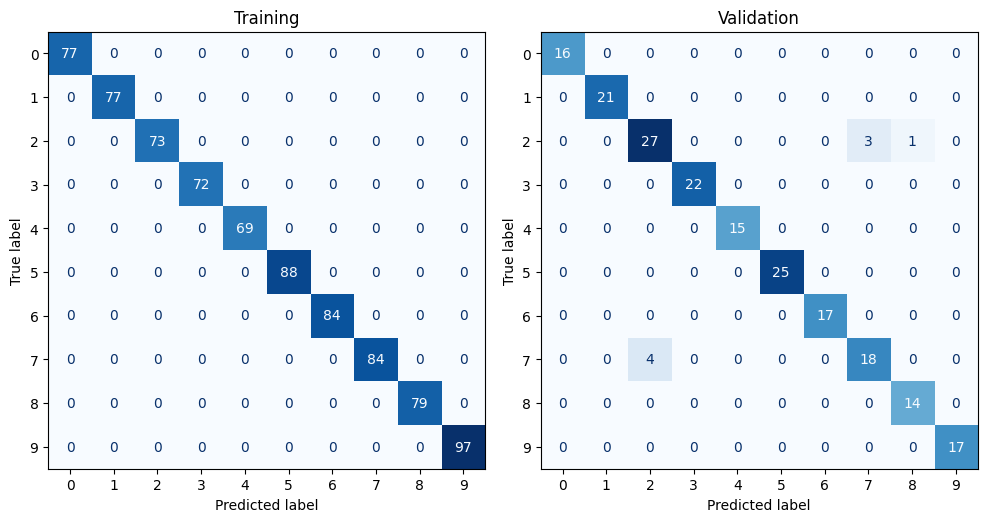

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1,2, figsize=(10,5))
for set, ax in zip([train_dataset, val_dataset], axes):
	x = set.tensors[0]
	all_true = set.tensors[1]
	all_pred = model.predict_label(x)

	cm = confusion_matrix(all_true, all_pred)
	disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
								display_labels = torch.arange(10).tolist())
	disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
axes[0].set_title('Training')
axes[1].set_title('Validation')
fig.tight_layout()

Most classes are recognized reliably. However, the model confuses structures of label 7/8 with label 2 in the validation set.

Even though the learning curves indicate overfitting, the model performance on validation data is consistent with the training performance. The discrepency may indicate that the overfitting primarily affects the confidence of the predictions rather than the predicted labels. For instance, the model may be very confident on one point in the training data with $p=0.999$ and thus have low CrossEntropyLoss, while the model is not very confident on one point in the validation data with $p=0.60$, therefore giving higher CrossEntropyLoss. Despite the higher loss, the model labels the structures accurately when taking argmax of the logits.

### Classes used for the cluster calculations

In [9]:
from week12 import ModifiedMorse
from week12 import AtomicCluster

ref_pos = [
	[[ 0.061, -0.735], [ 0.973, -0.810], [ 1.000, -1.757], [ 0.626, 0.543], [ -0.122, -1.662], [ -0.115, 0.069], [ 1.279, -0.047]],
	[[ 0.061, -0.735], [ -0.750, -0.129], [ 0.632, 0.041], [ -0.208, 0.630], [ -1.327, -0.848], [ 0.757, -1.343], [ -0.616, -1.515]],
	[[ 0.061, -0.735], [ 0.603, -0.097], [ -0.680, 0.453], [ -1.289, -1.071], [ -0.756, -0.379], [ 0.180, 0.659], [ 1.445, 0.075]], 
	[[ 0.061, -0.735], [ 0.880, -1.850], [ 0.315, 0.305], [ -0.609, 0.485], [ -0.810, -0.517], [ 0.983, -0.916], [ 1.228, 0.022]],
	[[ 0.061, -0.735], [ 0.060, -1.650], [ 1.050, -1.715], [ 1.178, -0.820], [ 0.196, 0.166], [ 1.216, 0.038], [ 1.356, 0.926]],
	[[ 0.061, -0.735], [ -0.491, 0.113], [ -1.858, 0.339], [ -2.059, -1.035], [ -1.300, -0.449], [ 0.844, -0.260], [ -0.694, -1.266]],
	[[ 0.061, -0.735], [ -1.285, -0.373], [ -0.074, 1.459], [ 0.417, 0.602], [ -0.929, 0.964], [ -0.434, 0.115], [ -0.794, -1.230]],
	[[ -0.010, -0.766], [ -0.129, 0.619], [ -0.594, -0.118], [ -0.706, 1.270], [ -0.471, -1.504], [ 0.689, 0.442], [ 0.765, -0.452]],
	[[ -0.064, -0.692], [ -0.059, 0.163], [ -1.393, -0.257], [ -0.870, 0.435], [ -0.889, -0.963], [ 0.432, -1.404], [ -1.383, 1.135]],
	[[ -0.064, -0.692], [ -0.443, -1.454], [ 0.186, -2.066], [ 1.898, -0.683], [ 0.828, -0.780], [ 0.914, 0.276], [ 0.937, -1.666]]
	]

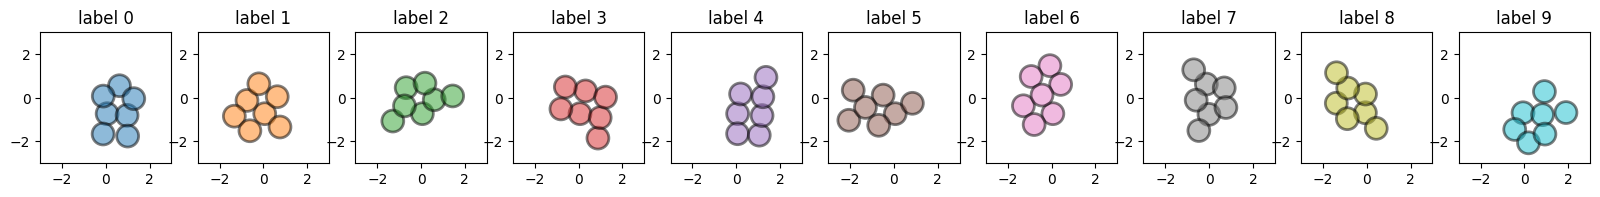

In [10]:
fig, axes = plt.subplots(1,10, figsize=(20,2))
calc = ModifiedMorse()
colors = [f'C{i}' for i in range(10)]
for i, pos in enumerate(ref_pos):
	ac = AtomicCluster(calc=calc, pos=pos)
	c = colors[i]
	ac.draw(axes[i], color=c)
	axes[i].set_xlim(-3,3)
	axes[i].set_ylim(-3,3)
	axes[i].set_aspect('equal')
	axes[i].set_title(f'label {i}')

It is possible to see why the model may have trouble distinguishing between label 2 and 7/ in the validation set. They look very similar but rotated. The descriptor probably encodes this rotation, and the model predicts well on training data, but slight differences in clusters means the model is "confused" about these two labels in unseen data (validation).

### Follow a cluster during cooling

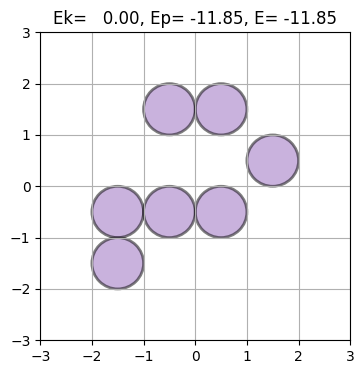

In [11]:
np.random.seed(3)

rand_x = [np.random.randint(-2,2) + 0.5]
rand_y = [np.random.randint(-2,2) + 0.5]

rand_pos = []

while len(rand_pos) < 7:
	x = np.random.randint(-2, 2) + 0.5
	y = np.random.randint(-2, 2) + 0.5

	point = (x, y)

	if point not in rand_pos:
		rand_pos.append(point)

rand_pos = torch.tensor(rand_pos, dtype=torch.float32)

fig, ax = plt.subplots(figsize=(4,4))
ac = AtomicCluster(calc=calc, pos=rand_pos)
ac.draw(ax)
ax.set_xlim(-3,3)
ax.set_ylim(-3,3)
ax.grid()

In [12]:
def velocity_verlet(mdsys, N=20):
	for _ in range(N):
		dt = 0.01
		r = mdsys.get_positions()
		v = mdsys.get_velocities()
		a_t = mdsys.forces # assume m=1

		# 1. update position
		r += v*dt + 1/2*a_t*dt**2
		mdsys.set_positions(r)

		# 2. evaluate force and acceleration at new step
		a_t_dt = mdsys.forces

		# 3. velocity update
		v += 1/2 * (a_t + a_t_dt)*dt
		mdsys.set_velocities(v)
	# remove kinetic energy
	mdsys.set_velocities(mdsys.get_velocities() * 0.8)

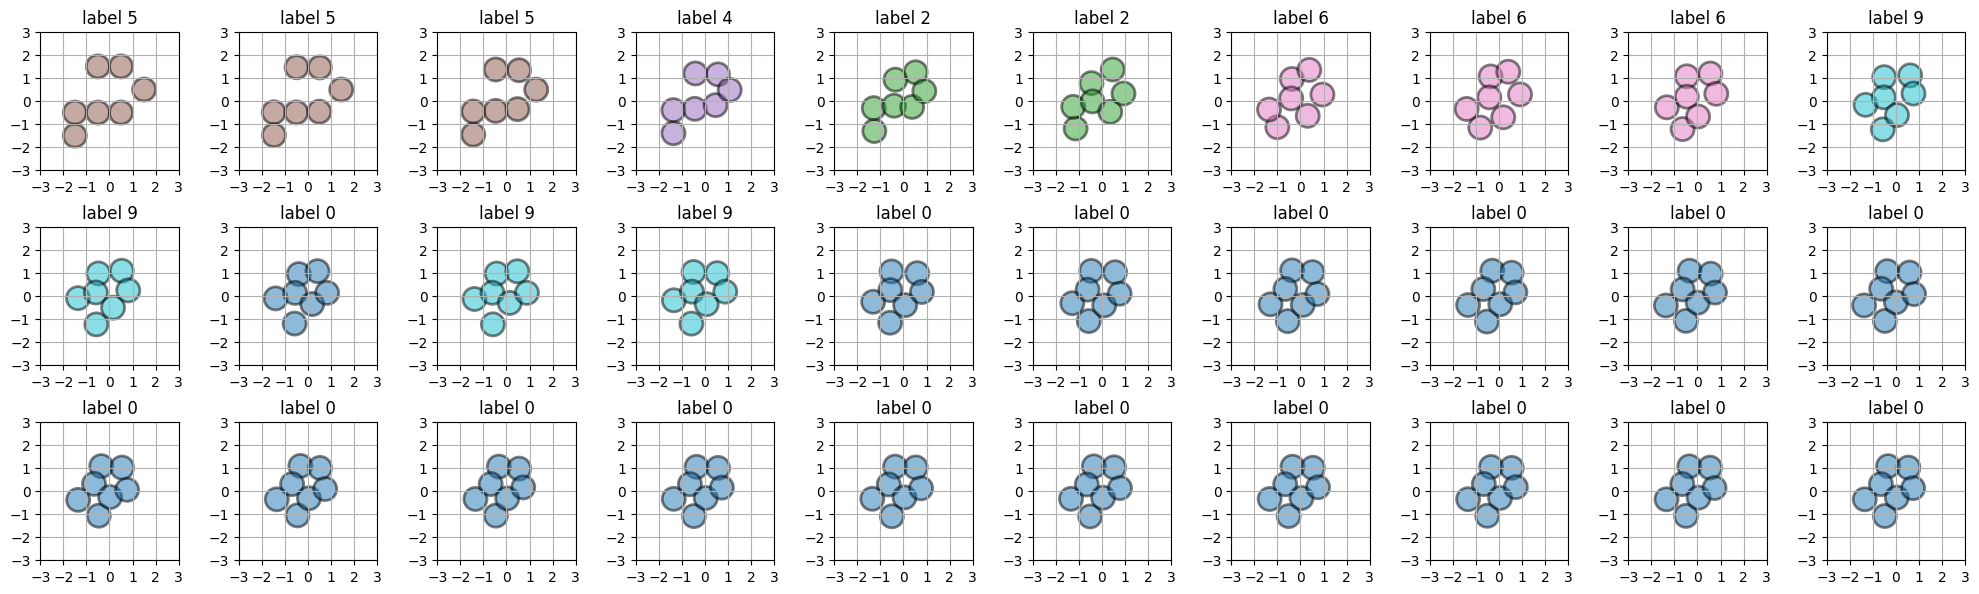

In [13]:
fig, axes = plt.subplots(3,10, figsize=(20,6))

def model_and_draw(ax, ac, model):
	descriptor = torch.tensor(ac.descriptor, dtype=torch.float32)
	pred_label = model.predict_label(descriptor)

	colors = [f'C{i}' for i in range(10)]
	c = colors[pred_label.item()]
	ac.draw(ax, color=c)

	ax.set_xlim(-3,3)
	ax.set_ylim(-3,3)
	ax.set_xticks(torch.arange(-3,3+1))
	ax.set_yticks(torch.arange(-3,3+1))
	ax.set_aspect('equal')
	ax.set_title(f'label {pred_label.item()}')
	ax.grid()

	return ac

ac = AtomicCluster(calc=calc, pos=rand_pos)
for ax in axes.flatten():
	model_and_draw(ax, ac, model)
	velocity_verlet(ac)
fig.tight_layout()

#### Again for another cooling trajectory

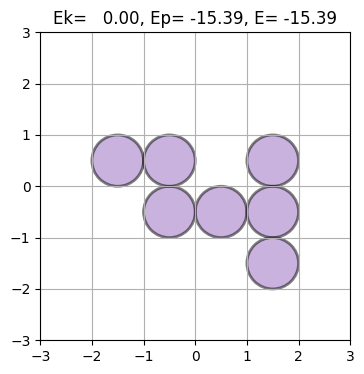

In [14]:
np.random.seed(6)

rand_x = [np.random.randint(-2,2) + 0.5]
rand_y = [np.random.randint(-2,2) + 0.5]

rand_pos = []

while len(rand_pos) < 7:
	x = np.random.randint(-2, 2) + 0.5
	y = np.random.randint(-2, 2) + 0.5

	point = (x, y)

	if point not in rand_pos:
		rand_pos.append(point)

rand_pos = torch.tensor(rand_pos, dtype=torch.float32)

fig, ax = plt.subplots(figsize=(4,4))
ac = AtomicCluster(calc=calc, pos=rand_pos)
ac.draw(ax)
ax.set_xlim(-3,3)
ax.set_ylim(-3,3)
ax.grid()

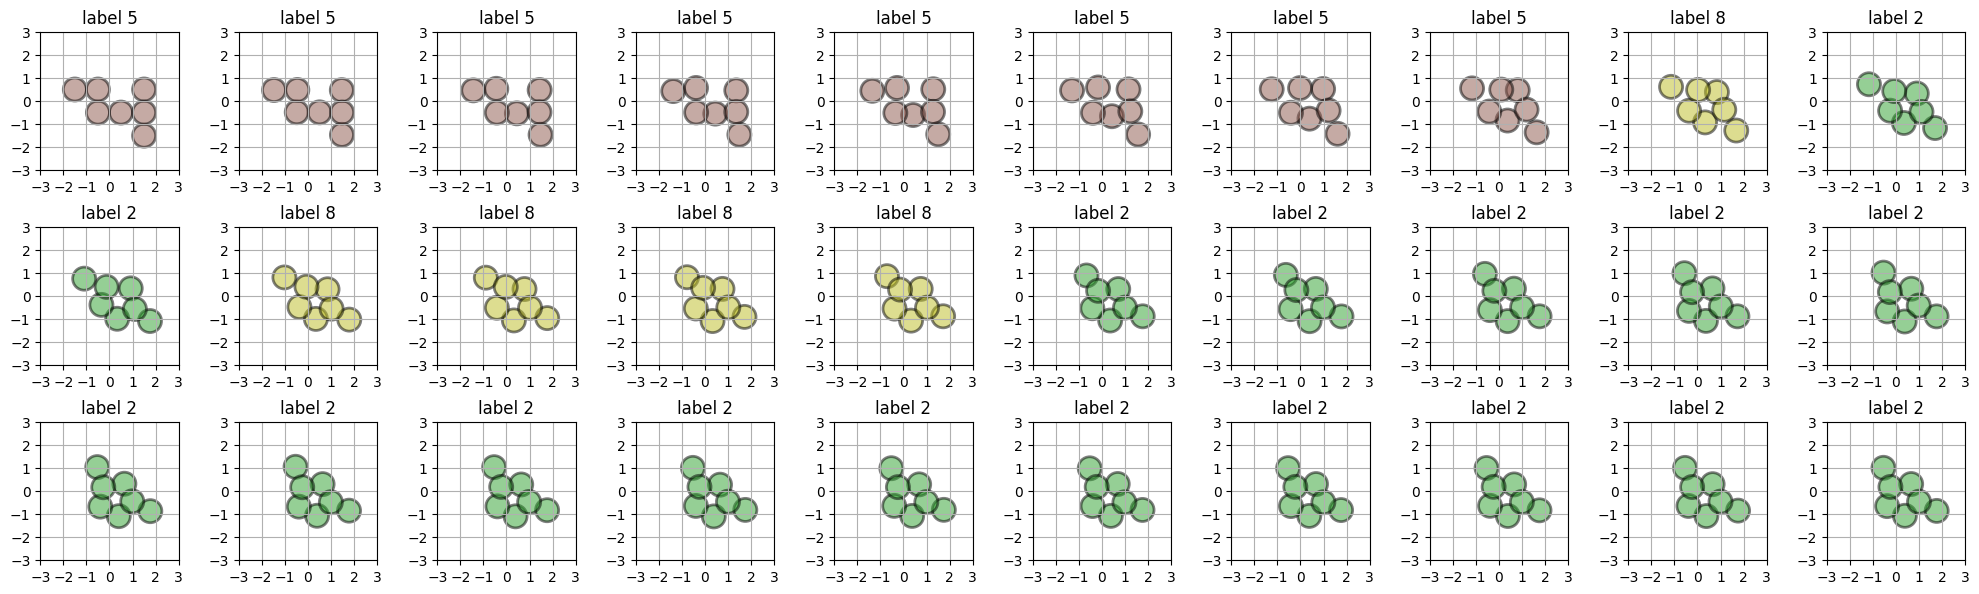

In [15]:
fig, axes = plt.subplots(3,10, figsize=(20,6))

def model_and_draw(ax, ac, model):
	descriptor = torch.tensor(ac.descriptor, dtype=torch.float32)
	pred_label = model.predict_label(descriptor)

	colors = [f'C{i}' for i in range(10)]
	c = colors[pred_label.item()]
	ac.draw(ax, color=c)

	ax.set_xlim(-3,3)
	ax.set_ylim(-3,3)
	ax.set_xticks(torch.arange(-3,3+1))
	ax.set_yticks(torch.arange(-3,3+1))
	ax.set_aspect('equal')
	ax.set_title(f'label {pred_label.item()}')
	ax.grid()

	return ac

ac = AtomicCluster(calc=calc, pos=rand_pos)
for ax in axes.flatten():
	model_and_draw(ax, ac, model)
	velocity_verlet(ac)
fig.tight_layout()

### Discussion

Once the clusters have relaxed into a compact structure, the class assignments are convincing. In both cases, the last 15 trajectories have the same prediction.

We should not expect the model to be confident in the early, highly distorted part of the trajectory. It is far from what it has seen in its training set, which was descriptors of relaxed structures.

In the early steps of relaxation, the network jumps suddenly between predictions. For the same reason as above, the structures look very different from its training set, so it would not make confident predictions. In the end of the trajectory, it looks more like its training data, and jumps are less likely, prediction changes are more smooth.

<br>

**Good point:**

If a model labels something that does not look like the other structures in that class, it is not, by itself, proof that an out-of-distribution structure belongs to that class. The classifier will always return one of its known labels and cannot create a new label when it's not confident.